# Billboard: Top 10 or Not?

**BA780 Final Project — Team A05**

Team members: Omar Tawfik, Caitlin Jeng, Muhammad Azaan, Xiaoquan Dai

---

### Project proposal

Among songs that entered the Billboard Hot 100 between January 2018 and September 2026, what
separates those that climbed into the **Top 10** from those that peaked lower, and can we
spot a future Top 10 hit in its **debut week**, using only what a label knows at that point?

The Team Assignment (Phase 1) tested ten factors one at a time. This final phase goes deeper:
a prediction model judged on years it has never seen, a fairer test of the album-drop
penalty, how hits move on the chart week by week, and two trends in how songs are made
(song length and collaborations).

### Data sources, access and licensing

| Source | What we used | Access URL | Licence |
|---|---|---|---|
| Billboard Hot 100 weekly archive (mhollingshead) | every weekly chart, 1958-2026 | https://github.com/mhollingshead/billboard-hot-100 | **No licence declared by the repository.** The chart itself is Billboard's copyrighted compilation |
| LRCLIB | song lyrics | https://lrclib.net/docs | **No licence stated on the public docs page.** Lyrics belong to their rights holders |
| MusicBrainz | release dates, genres, song length, artist data | https://musicbrainz.org/doc/MusicBrainz_API | Core data **CC0 / public domain** |

We use the two unlicensed sources for non-commercial academic analysis only, and we do not
redistribute the lyrics or the chart archive.

### How to run this notebook

- **Billboard:** read from `data/raw/all.json` if it exists, otherwise downloaded from
  GitHub (44 MB). Either way we keep charts up to **2026-09-19**, so the results do not
  change when new weeks are added.
- **Lyrics and MusicBrainz:** in Colab, upload `raw_api_data.zip` (4 MB) when asked.
  Locally the files are read from `data/raw/`. The notebook makes no API calls; the
  collection scripts in `scripts/` fetched these files once.
- Runs top to bottom in about a minute.

In [1]:
import os
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats      # used only for the two significance tests in Section 4

np.random.seed(42)

## Executive summary

**Objective.** Help a record label decide, in a song's release week, which songs deserve
Top 10 marketing money and which release choices improve the odds.

**Data and methods.** 5,342 songs that entered the Hot 100 from January 2018 to September 2026,
joined to lyrics (LRCLIB) and release data (MusicBrainz). About one song in ten reaches the
Top 10. We tested factors with chi-square and Mann-Whitney tests on 2018-2024, then trained a
logistic regression on 2018-2024 and judged it once on the 950 songs of 2025-2026.

**Key findings.**

1. **A debut-week model works as a screening tool.** Of the 35 test songs it flagged, 15 became
   Top 10 hits (**42.9% precision**), against 5.9% for a random pick and 19.6% for a model that
   only knows the artist's history. It caught 15 of the 56 real hits (**26.8% recall**).
2. **How a song is released is the biggest lever a label controls.** Holding the artist fixed,
   **38 of 63 artists** did better with songs released on their own than with songs in an album
   drop of five or more; only 8 did better in drops. Drake: 70.0% alone vs 26.5% in drops.
3. **The debut week decides most hits.** 58.4% of Top 10 hits peak in their first week, up from
   46.3% for 2018 debuts to 57.8% in 2025, and recent hits fade faster after it.
4. **Several popular ideas do not hold up.** Lyric style, featured artists and collaborations,
   explicit lyrics and the release month make little or no difference. Songs are getting
   shorter (3.40 → 3.18 minutes), but hits are not: they run about 8 seconds *longer*.

**Recommendations.**

- **Release priority singles on their own, before the album.** Avoid mid-sized drops: songs in
  a 5-9 song drop reach the Top 10 only 2.1% of the time.
- **Front-load the marketing budget into release week.** There is rarely a second chance.
- **Use the model to rank songs for attention, not to promise hits.** It finds hits at about
  seven times the random rate, but still misses most of them.
- **Do not chase surface features** (shorter songs, a featured verse, a "best month").

**Next step.** Re-score the model on the full 2026 season once those songs finish charting,
and add audio and streaming features that a label has before release.

## 1. Introduction & motivation

**Why read this?** Around 600 new songs enter the Hot 100 every year, and only one in ten
reaches the Top 10, where most radio play, playlist placement and revenue go. Labels have to
decide how to release and promote a song *before* they know how it will do. Advice like "make
a better song" does not help with that decision. "Release this as a single rather than as
track nine of an album" does. This notebook measures which levers matter, using only what a
label knows in a song's first week.

**How we frame it.**

- **Unit:** one song, identified by its title and the artist credit it debuted under.
- **Target:** `top10`, whether the song ever reached positions 1-10.
- **Population:** songs whose *first* week on the chart is on or after 2018-01-01, so every
  song is observed from the start of its run. Songs still on the last chart are left out of
  every test, because their peak is not final.
- **Predictors:** only what was known in the debut week: the artist's earlier chart record,
  genre, lyrics, song length, release date, and how many songs the artist released that week.
- **Train and test:** 2018-2024 songs are used for every test and to train the model;
  2025-2026 songs are held back to judge the model once.

**Success criteria.** This phase succeeds if it delivers two things: a clean, documented dataset of every 2018–2026 Hot 100 song with only debut-week predictors, and a ranked list of the factors that genuinely separate Top 10 hits from lower-peaking songs. We count a factor as meaningful only if the difference is statistically significant (p < 0.05) **and** at least a small effect (Cramér's V ≥ 0.1), since with thousands of songs even trivial differences can pass a significance test. In the final phase, success means a prediction model trained on 2018–2024 that identifies Top 10 hits in the held-out 2025–2026 songs better than a simple baseline using artist history alone, judged by precision and recall rather than accuracy.

## 2. Data description

| File | One row per | Rows | Key columns we use |
|---|---|---|---|
| `all.json` (Billboard) | song per chart week | 355,487 rows in 3,555 weekly charts, 1958-2026 | date, song, artist, position |
| `lyrics.csv` (LRCLIB) | chart credit | 5,377 | lyrics text, instrumental flag, duration, match score |
| `mb_songs.csv` (MusicBrainz) | chart credit | 5,349 | release date, recording length, genres and vote counts, artist ids, match score |
| `mb_artists.csv` (MusicBrainz) | artist | 1,269 | genres and vote counts |

We keep the whole archive back to 1958, even though the study starts in 2018, because an
artist's earlier record must be counted from all of chart history: Drake's count of
earlier hits would be wrong if we only looked back to 2018.

LRCLIB and MusicBrainz were matched to Billboard songs by name, so each match has a
confidence score from 0 to 100. We treat 72 or more as a trusted match.

**So what:** one chart archive is the backbone; lyrics and MusicBrainz add information about each song.

## 3. Data cleaning

All cleaning happens in this section, starting from the raw files. Each step prints a
before/after count so the effect of every change is visible.

### Step 1. Load and inspect

In Colab, the first cell asks for one upload, `raw_api_data.zip`, and unzips it into
`data/raw/`. Locally the CSV files are already there.

In [2]:
# In Colab, upload raw_api_data.zip once. Locally, the three CSV files are already in data/raw/.
if not os.path.exists('data/raw/lyrics.csv'):
    from google.colab import files
    files.upload()                                     # choose raw_api_data.zip
    with zipfile.ZipFile('raw_api_data.zip') as upload:
        upload.extractall('data/raw')

print(os.listdir('data/raw'))

['mb_songs.csv', 'mb_artists.csv', 'lyrics.csv', 'all.json']


The Billboard archive is one JSON file with a row per week; each week holds a list of 100
songs. We read the local copy if there is one, otherwise the file on GitHub.

In [3]:
BILLBOARD_URL = 'https://raw.githubusercontent.com/mhollingshead/billboard-hot-100/main/all.json'
LAST_CHART = '2026-09-19'   # the last week we analysed; charts added later are ignored

if os.path.exists('data/raw/all.json'):
    charts = pd.read_json('data/raw/all.json')
else:
    charts = pd.read_json(BILLBOARD_URL)

print(len(charts), 'weekly charts downloaded')
charts.head(3)

3555 weekly charts downloaded


,date,data
0,1958-08-04,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
1,1958-08-11,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
2,1958-08-18,"[{'song': 'Nel Blu Dipinto Di Blu (Volare)', '..."


Each week's list is turned into one row per song per week with a simple `for` loop. Then
we convert the date column to a real date and keep only charts up to 2026-09-19.

In [4]:
rows = []
for i in range(len(charts)):
    for entry in charts['data'][i]:
        rows.append([charts['date'][i], entry['song'], entry['artist'], entry['this_week']])

weekly = pd.DataFrame(rows, columns=['chart_date', 'title', 'artist', 'position'])
weekly['chart_date'] = pd.to_datetime(weekly['chart_date'])
weekly = weekly[weekly['chart_date'] <= LAST_CHART]

print('weekly charts kept:', len(weekly['chart_date'].unique()))
print('chart rows:', len(weekly))
weekly.head(3)

weekly charts kept: 3555
chart rows: 355487


,chart_date,title,artist,position
0,1958-08-04,Poor Little Fool,Ricky Nelson,1
1,1958-08-04,Patricia,Perez Prado And His Orchestra,2
2,1958-08-04,Splish Splash,Bobby Darin,3


No missing values and no fully duplicated rows. The 13 rows where the same title and artist
appear twice in one week are real: in 1990 two different recordings of "Unchained Melody"
by The Righteous Brothers were on the chart at the same time. They are from before 2018
and only affect that act's own history, so we leave them.

In [5]:
print('rows and columns:', weekly.shape)
print('missing values in any column:', weekly.isna().sum().sum())
print('duplicate rows:', weekly.duplicated().sum())
print('same song twice in one week:', weekly.duplicated(subset=['chart_date', 'title', 'artist']).sum())

rows and columns: (355487, 4)
missing values in any column: 0
duplicate rows: 0


same song twice in one week: 13


Now the three files of API results. We keep only the columns we use.

In [6]:
lyrics = pd.read_csv('data/raw/lyrics.csv')
lyrics = lyrics[['title', 'artist', 'plain_lyrics', 'instrumental', 'duration', 'match_score']]

mb_songs = pd.read_csv('data/raw/mb_songs.csv')
mb_songs = mb_songs[['title', 'artist', 'first_release_date', 'recording_length_ms',
                     'genres', 'genre_counts', 'artist_mbids', 'match_score']]

mb_artists = pd.read_csv('data/raw/mb_artists.csv')
mb_artists = mb_artists[['artist_mbid', 'genres', 'genre_counts']]

print('lyrics:', lyrics.shape, '| mb_songs:', mb_songs.shape, '| mb_artists:', mb_artists.shape)

lyrics: (5377, 6) | mb_songs: (5349, 8) | mb_artists: (1269, 3)


Missing values here are expected: 33 songs have no lyrics text (no match, or an
instrumental), and 1,605 MusicBrainz recordings have no genre. Each file has exactly one
row per key, so the joins in Step 7 can be checked with `validate='one_to_one'`.

In [7]:
# Show only the columns that have missing values.
lyrics_missing = lyrics.isna().sum()
mb_missing = mb_songs.isna().sum()
print('lyrics, missing values:', lyrics_missing[lyrics_missing > 0].to_dict())
print('MusicBrainz songs, missing values:', mb_missing[mb_missing > 0].to_dict())
print('duplicate keys:', lyrics.duplicated(subset=['title', 'artist']).sum(),
      mb_songs.duplicated(subset=['title', 'artist']).sum(),
      mb_artists.duplicated(subset=['artist_mbid']).sum())

lyrics, missing values: {'plain_lyrics': 33, 'instrumental': 32, 'duration': 283}
MusicBrainz songs, missing values: {'first_release_date': 17, 'recording_length_ms': 3033, 'genres': 1605, 'genre_counts': 1605, 'artist_mbids': 56}
duplicate keys: 0 0 0


### Step 2. Weekly rows → one row per chart credit

The archive repeats a song every week it is on the chart. We collapse it to one row per
title and artist credit: first and last week, best (lowest) position, debut position and
number of weeks. We write this as a function because Step 3 repeats it.

In [8]:
def one_row_per_song(weekly):
    """Collapse the weekly chart rows into one row per (title, artist)."""
    weekly = weekly.sort_values('chart_date')
    songs = weekly.groupby(['title', 'artist']).agg(
        debut_date=('chart_date', 'min'),
        last_date=('chart_date', 'max'),
        peak_position=('position', 'min'),
        debut_position=('position', 'first'),
        weeks_on_chart=('chart_date', 'count'),
    ).reset_index()
    songs['top10'] = songs['peak_position'] <= 10
    return songs

In [9]:
credits = one_row_per_song(weekly)
credits_2018 = credits[credits['debut_date'] >= '2018-01-01']

print('chart rows:', len(weekly), '-> chart credits:', len(credits))
print('credits that debuted in 2018 or later:', len(credits_2018))
print('of those, reached the Top 10:', credits_2018['top10'].sum())
credits.head(3)

chart rows: 355487 -> chart credits: 32723
credits that debuted in 2018 or later: 5377
of those, reached the Top 10: 521


,title,artist,debut_date,last_date,peak_position,debut_position,weeks_on_chart,top10
0,"""B"" Girls",Young And Restless,1990-05-05,1990-08-11,54,84,15,False
1,"""Cherry Cherry"" from Hot August Night",Neil Diamond,1973-03-17,1973-05-19,31,84,10,False
2,"""Having A Party"" Medley",The Ovations (Featuring Louis Williams),1973-10-13,1973-12-08,56,99,9,False


### Step 3. Merge songs that Billboard listed under two credits

Sometimes Billboard changes a song's credit while it is on the chart ("Kanye West" became
"Ye"; a featured artist is added). The song then appears as two rows, which splits its
weeks and understates its peak. Our team reviewed every candidate pair by hand and kept
**34 songs** to merge. They are written out below as a plain list: each line renames a
later credit to the credit the song **debuted** under.

We rejected pairs that only looked alike: songs that were on the chart in the same week,
and different recordings such as "White Christmas (1947)" and V & Bing Crosby's version.

In [10]:
DUPLICATE_CREDITS = [
    ['360', 'Charli xcx',
     '360', 'Charli XCX'],
    ['Act II: Date @ 8', '4Batz Featuring Drake',
     'Act II: Date @ 8', '4Batz'],
    ['Ahi', 'Karol G With Drake',
     'Ahi', 'Karol G & Drake'],
    ['Apple', 'Charli xcx',
     'Apple', 'Charli XCX'],
    ['BbY WOW', 'Karol G With Judeline & rusowsky',
     'BbY WOW', 'Karol G, Judeline & rusowsky'],
    ['Blue Strips', 'jessie murph',
     'Blue Strips', 'Jessie Murph'],
    ['Bottle Rockets', 'Scotty McCreery & Hootie & the Blowfish',
     'Bottle Rockets', 'Scotty McCreery & Hootie & The Blowfish'],
    ['Burn', '¥$: Ye & Ty Dolla $ign',
     'Burn', '¥$: Kanye West & Ty Dolla $ign'],
    ['Burning Blue', 'Mariah the Scientist',
     'Burning Blue', 'Mariah The Scientist'],
    ['Carnival', '¥$: Ye & Ty Dolla $ign Featuring Rich The Kid & Playboi Carti',
     'Carnival', '¥$: Kanye West & Ty Dolla $ign Featuring Rich The Kid & Playboi Carti'],
    ['Dial Drunk', 'Noah Kahan With Post Malone',
     'Dial Drunk', 'Noah Kahan'],
    ['Dracula', 'Tame Impala & JENNIE',
     'Dracula', 'Tame Impala'],
    ['Ever Since U Left Me (I Went Deaf)', 'French Montana & Max B',
     'Ever Since U Left Me', 'Max B & French Montana'],
    ['Fuk Sumn', '¥$: Ye & Ty Dolla $ign',
     'Fuk Sumn', '¥$: Kanye West & Ty Dolla $ign'],
    ['Get In With Me', 'BossMan DLow',
     'Get In With Me', 'BossMan Dlow'],
    ['Go Away', 'Weezer Featuring Best Coast',
     'Go Away', 'Weezer'],
    ['Golden', 'HUNTR/X: EJAE, Audrey Nuna & REI AMI',
     'Golden', 'HUNTR/X, EJAE, Audrey Nuna & Rei Ami'],
    ['Hard Fought Hallelujah', 'Brandon Lake X Jelly Roll',
     'Hard Fought Hallelujah', 'Brandon Lake'],
    ['Hell At Night', 'BigXthaPlug Featuring Ella Langley',
     'Hell At Night', 'BigXthaPlug & Ella Langley'],
    ["I Ain't Coming Back", 'Morgan Wallen Featuring Post Malone',
     "I Ain't Coming Back", 'Morgan Wallen & Post Malone'],
    ['Is It A Crime', 'Mariah The Scientist & Kali Uchis',
     'Is It A Crime', 'Mariah the Scientist & Kali Uchis'],
    ['Jingle Bells', 'Frank Sinatra With Orchestra Conducted By Gordon Jenkins',
     'Jingle Bells', 'Frank Sinatra'],
    ['Jingle Bells', 'Frank Sinatra With The Orchestra & Chorus Of Gordon Jenkins',
     'Jingle Bells', 'Frank Sinatra'],
    ['Karma', 'Taylor Swift Featuring Ice Spice',
     'Karma', 'Taylor Swift'],
    ["Let's Go", 'Key Glock & Young Dolph',
     "Let's Go", 'Key Glock'],
    ['One More Time', 'blink-182',
     'One More Time', 'Blink-182'],
    ['One Of The Girls', 'The Weeknd, Jennie & Lily Rose Depp',
     'One Of The Girls', 'The Weeknd, JENNIE & Lily Rose Depp'],
    ['Shake Dat Ass (Twerk Song)', 'BossMan Dlow',
     'Shake Dat Ass (Twerk Song)', 'BossMan DLow'],
    ['Soak City', '310babii',
     'Soak City (Do It)', '310babii'],
    ['Still', 'Karol G With Bruno Mars',
     'Still', 'Karol G & Bruno Mars'],
    ['Sugar On My Tongue', 'Tyler, The Creator',
     'Sugar On My Tongue', 'Tyler, the Creator'],
    ['Take Me Thru Dere', 'Metro Boomin, Quavo, Breskii & YKNIECE',
     'Take Me Thru Dere', 'Metro Boomin, Quavo, Breskii & YK NIECE'],
    ['Tweaker', 'GELO',
     'Tweaker', 'Gelo'],
    ['Typa', 'Glorilla',
     'Typa', 'GloRilla'],
    ['Your Idol', 'Saja Boys: Andrew Choi, Neckwav, Danny Chung, Kevin Woo & samUIL Lee',
     'Your Idol', 'Saja Boys, Andrew Choi, Neckwav, Danny Chung, Kevin Woo & samUIL Lee'],
]

Apply the renames to the weekly rows, then rebuild the song table. Two songs, "Carnival" and
"Karma", had been counted as two separate Top 10 hits, so the Top 10 count drops by two.

In [11]:
for old_title, old_artist, new_title, new_artist in DUPLICATE_CREDITS:
    match = (weekly['title'] == old_title) & (weekly['artist'] == old_artist)
    weekly.loc[match, 'title'] = new_title
    weekly.loc[match, 'artist'] = new_artist

songs = one_row_per_song(weekly)
songs_2018 = songs[songs['debut_date'] >= '2018-01-01']

print('songs from 2018 on:', len(credits_2018), '->', len(songs_2018))
print('Top 10 songs from 2018 on:', credits_2018['top10'].sum(), '->', songs_2018['top10'].sum())
print('same song twice in one week:', weekly.duplicated(subset=['chart_date', 'title', 'artist']).sum())

songs from 2018 on: 5377 -> 5342
Top 10 songs from 2018 on: 521 -> 519
same song twice in one week: 13


For example, "Carnival" now has one row with its full chart run and its best position.

In [12]:
check = songs_2018[songs_2018['title'].isin(['Carnival', 'Karma', 'Golden'])]
check[['title', 'artist', 'debut_date', 'peak_position', 'weeks_on_chart']]

,title,artist,debut_date,peak_position,weeks_on_chart
4325,Carnival,¥$: Kanye West & Ty Dolla $ign Featuring Rich ...,2024-02-24,1,19
9570,Golden,"HUNTR/X, EJAE, Audrey Nuna & Rei Ami",2025-07-05,1,47
9571,Golden,Harry Styles,2019-12-28,57,20
15096,Karma,Queen Naija,2018-07-14,63,2
15097,Karma,Rod Wave,2024-10-26,100,1
15098,Karma,Taylor Swift,2022-11-05,2,30


### Step 4. Split each credit into individual artists

"Bruno Mars & Cardi B" is two artists. To count each artist's history, we lowercase the
credit, replace every separator Billboard uses with `|`, and split on `|`. A few names
contain a separator but are one act; we protect those by rewriting them first.

We tested every protected name from an earlier, longer list: only these three change any
2018+ song's results, so the list stays this short.

In [13]:
# Names that contain a separator but are one act. Each is rewritten so the split leaves it whole.
PROTECTED_NAMES = {
    'lil nas x': 'lil nas-x',          # " x " would cut "Lil Nas X & Jack Harlow" in the wrong place
    'sam & dave': 'sam and dave',      # keeps the 1960s duo out of the UK rapper Dave's history
    'sonny & cher': 'sonny and cher',  # keeps the duo's hits out of Cher's solo history
}

# Words Billboard uses between artists, including its own typos ("Feauring").
# Longer phrases come first so " a duet with " is removed before " with ".
SEPARATORS = [' a duet with ', ' duet with ', ' featuring ', ' feauring ', ' featauring ',
              ' feat. ', ' feat ', ' ft. ', ' with ', ' w/ ', ' vs. ', ' vs ',
              ' introducing ', ' presents ', ' x ', ' & ', ', ', ': ', ' (']

In [14]:
names = songs['artist'].str.lower()
names = names.str.replace('"', '', regex=False).str.replace(')', '', regex=False)
for name, safe_name in PROTECTED_NAMES.items():
    names = names.str.replace(name, safe_name, regex=False)
for separator in SEPARATORS:
    names = names.str.replace(separator, '|', regex=False)

artist_columns = names.str.split('|', expand=True)
songs['primary_artist'] = artist_columns[0].str.strip()
songs['has_feature'] = songs['artist'].str.lower().str.contains(r'featuring|feauring|featauring|feat\.|ft\.')
songs['n_credited_artists'] = artist_columns.notna().sum(axis=1)   # used in Phase 2, Q5

print('most artists in one credit:', artist_columns.shape[1])

most artists in one credit: 10


Some examples. The first column is the lead (primary) artist. "¥$" keeps its members as
separate artists, so Kanye West's history still counts on ¥$ songs. We also keep the number
of artists in each credit (`n_credited_artists`) for Phase 2, Q5.

In [15]:
examples = ['Bruno Mars & Cardi B', 'Lil Nas X & Jack Harlow', '¥$: Ye & Ty Dolla $ign',
            'Silk Sonic (Bruno Mars & Anderson .Paak)', 'Iggy Azalea Feauring Tyga']
is_example = songs['artist'].isin(examples)
pd.concat([songs.loc[is_example, ['artist']], artist_columns[is_example]], axis=1).drop_duplicates('artist')

,artist,0,1,2,3,4,5,6,7,8,9
3201,Silk Sonic (Bruno Mars & Anderson .Paak),silk sonic,bruno mars,anderson .paak,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8181,Bruno Mars & Cardi B,bruno mars,cardi b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14065,Lil Nas X & Jack Harlow,lil nas-x,jack harlow,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15397,Iggy Azalea Feauring Tyga,iggy azalea,tyga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 5. Each artist's chart history before the song debuted

First we stack the split columns into one row per (song, artist). A song credited to
"Bruno Mars & Cardi B" appears once under each artist.

In [16]:
# One row per (song, credited artist): stack the split columns on top of each other.
pieces = []
for column in artist_columns.columns:
    piece = songs[['title', 'artist', 'debut_date', 'top10']].copy()
    piece['artist_name'] = artist_columns[column].str.strip()
    pieces.append(piece)

artist_songs = pd.concat(pieces)
artist_songs = artist_songs.dropna(subset=['artist_name'])
artist_songs = artist_songs[artist_songs['artist_name'] != '']
artist_songs = artist_songs.drop_duplicates(subset=['title', 'artist', 'artist_name'])

print('songs:', len(songs), '-> song-artist rows:', len(artist_songs))

songs: 32688 -> song-artist rows: 39939


Then we merge every 2018+ song with all songs by its lead artist, keep only the songs that
debuted **strictly earlier**, and count them. Songs released in the same week do not
count as "earlier", so nothing from the song's own debut leaks in.

In [17]:
earlier_songs = artist_songs.rename(columns={
    'title': 'earlier_title', 'artist': 'earlier_artist',
    'debut_date': 'earlier_debut', 'top10': 'earlier_top10', 'artist_name': 'primary_artist'})

recent = songs[songs['debut_date'] >= '2018-01-01']
pairs = pd.merge(recent[['title', 'artist', 'debut_date', 'primary_artist']],
                 earlier_songs, on='primary_artist', how='left')
earlier = pairs[pairs['earlier_debut'] < pairs['debut_date']]

history = earlier.groupby(['title', 'artist']).agg(
    prior_entries=('earlier_title', 'count'),
    prior_top10s=('earlier_top10', 'sum'),
).reset_index()
print('recent songs:', len(recent), '| (song, earlier song) pairs:', len(earlier),
      '| songs with any history:', len(history))

recent songs: 5342 | (song, earlier song) pairs: 241042 | songs with any history: 4831


Two leakage checks. A song must never count itself, and a slow recount of 200 random songs,
done one at a time, must give the same numbers.

In [18]:
# Check 1: no song is ever counted in its own history.
self_counted = (earlier['earlier_title'] == earlier['title']) & (earlier['earlier_artist'] == earlier['artist'])
print('songs counted in their own history:', self_counted.sum())

# Check 2: recount 200 random songs the slow way and compare.
sample = recent.sample(200, random_state=42)
mismatches = 0
for i in sample.index:
    same_artist = artist_songs[artist_songs['artist_name'] == sample.loc[i, 'primary_artist']]
    before = same_artist[same_artist['debut_date'] < sample.loc[i, 'debut_date']]
    found = history[(history['title'] == sample.loc[i, 'title']) & (history['artist'] == sample.loc[i, 'artist'])]
    if before['top10'].sum() != found['prior_top10s'].sum():
        mismatches = mismatches + 1
print('mismatches in 200 recounted songs:', mismatches)

songs counted in their own history: 0


mismatches in 200 recounted songs: 0


### Step 6. Keep songs that debuted in 2018 or later, and add the target

We now drop songs that debuted before 2018 (they were only needed for history), add the
history counts, and mark songs still on the last chart: their peak is not final.

In [19]:
last_week = weekly['chart_date'].max()
print('all songs in the archive:', len(songs))

songs = songs[songs['debut_date'] >= '2018-01-01'].copy()
songs = pd.merge(songs, history, on=['title', 'artist'], how='left', validate='one_to_one')
songs['prior_entries'] = songs['prior_entries'].fillna(0)
songs['prior_top10s'] = songs['prior_top10s'].fillna(0)

songs['still_charting'] = songs['last_date'] == last_week
songs['in_model'] = ~songs['still_charting']
songs['debut_year'] = songs['debut_date'].dt.year
songs['debut_month'] = songs['debut_date'].dt.month
print('songs that debuted in 2018 or later:', len(songs))

all songs in the archive: 32688
songs that debuted in 2018 or later: 5342


Songs from 2018-2024 are the training set used for every test, and to train the model in Section 5. Songs from
2025-2026 are held back as a test set. Songs still charting are excluded.

In [20]:
songs['model_split'] = 'train'
songs.loc[songs['debut_year'] >= 2025, 'model_split'] = 'test'
songs.loc[songs['still_charting'], 'model_split'] = 'excluded'

songs.groupby('model_split').agg(songs=('title', 'size'), top10=('top10', 'sum'))

,songs,top10
model_split,,
excluded,99,22
test,950,56
train,4293,441


### Step 7. Join lyrics and MusicBrainz

Left joins keep every song. `validate='one_to_one'` stops the code if a key appears twice,
and `indicator=True` shows how many songs found a match.

In [21]:
lyrics = lyrics.rename(columns={'match_score': 'lyrics_match_score'})
before = len(songs)
songs = pd.merge(songs, lyrics, on=['title', 'artist'], how='left',
                 validate='one_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')

print('rows before and after:', before, len(songs))
print('lyrics matched with confidence 72+:', (songs['lyrics_match_score'] >= 72).sum())

_merge
both          5342
left_only        0
right_only       0
Name: count, dtype: int64
rows before and after: 5342 5342
lyrics matched with confidence 72+: 5309


In [22]:
mb_songs = mb_songs.rename(columns={'match_score': 'mb_match_score', 'genres': 'song_genres',
                                    'genre_counts': 'song_genre_counts'})
songs = pd.merge(songs, mb_songs, on=['title', 'artist'], how='left',
                 validate='one_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')
print('MusicBrainz matched with confidence 72+:', (songs['mb_match_score'] >= 72).sum())

_merge
both          5342
left_only        0
right_only       0
Name: count, dtype: int64
MusicBrainz matched with confidence 72+: 5287


Artist genres come from the lead artist's MusicBrainz record. 55 songs have no MusicBrainz
artist, so they get no artist genres.

In [23]:
songs['lead_mbid'] = songs['artist_mbids'].str.split('|', expand=True)[0]
mb_artists = mb_artists.rename(columns={'artist_mbid': 'lead_mbid', 'genres': 'artist_genres',
                                        'genre_counts': 'artist_genre_counts'})
songs = pd.merge(songs, mb_artists, on='lead_mbid', how='left',
                 validate='many_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')
print('rows:', len(songs))

_merge
both          5287
left_only       55
right_only       0
Name: count, dtype: int64
rows: 5342


### Step 8. Broad genre

MusicBrainz uses hundreds of detailed labels ("cloud rap", "dance-pop"). We map each label to
one of eight broad genres with simple keyword rules, add up the votes per broad genre, and
take the one with the most votes.

**Latin** means Spanish- or Portuguese-language Latin American music, so Brazilian funk is
Latin while reggae and dancehall are "other". Keywords match whole words, so "rap" matches
"pop rap" but not inside another word.

In [24]:
# Keywords for each broad genre. One-word keywords must match a whole word of the label
# ("rap" matches "pop rap" but not "grape"); two-word keywords match as a phrase.
LATIN = ['latin', 'latino', 'latina', 'reggaeton', 'regueton', 'salsa', 'bachata', 'cumbia',
         'corrido', 'corridos', 'banda', 'mariachi', 'tejano', 'merengue', 'dembow', 'norteño',
         'norteno', 'ranchera', 'mexican', 'mexicano', 'bolero', 'flamenco', 'samba', 'bossa',
         'brazilian', 'brasileiro', 'brasileira', 'carioca', 'ostentação', 'brega', 'sertanejo',
         'español', 'espanol', 'portuguese']
COUNTRY = ['country', 'bluegrass', 'americana', 'honky', 'nashville', 'urban cowboy']
HIPHOP = ['hip hop', 'hiphop', 'rap', 'trap', 'drill', 'grime', 'crunk', 'boom bap', 'bounce',
          'hyphy', 'dirty south', 'rage', 'plugg', 'horrorcore', 'ratchet']
RNB = ['funk', 'funky', 'funktronica', 'motown', 'new jack swing', 'quiet storm', 'doo wop']
ROCK = ['rock', 'punk', 'metal', 'grunge', 'indie', 'alternative', 'emo', 'shoegaze',
        'blackgaze', 'britpop', 'new wave', 'psychedelia']
DANCE = ['electronic', 'electronica', 'electro', 'edm', 'house', 'techno', 'trance', 'dubstep',
         'dance', 'disco', 'club', 'rave', 'drum and bass', 'dnb', 'bass', 'synthwave',
         'eurodance', 'hardstyle', 'garage', 'trip hop', 'complextro', 'downtempo', 'leftfield',
         'indietronica', 'jungle', 'ambient', 'tronica', 'breakbeat', 'moombahton', 'brostep',
         'ebm', 'hardcore']

In [25]:
def has_keyword(label, keywords):
    """True if the label contains one of the keywords as a whole word or phrase."""
    label = label.replace('-', ' ')
    words = label.split()
    for keyword in keywords:
        if ' ' in keyword and keyword in label:
            return True
        if keyword in words:
            return True
    return False

The rules are checked in order and the first match wins, so "latin pop" is Latin and
"country pop" is country, while "pop rap" is rap and "dance-pop" is pop.

In [26]:
def broad_genre(label):
    """Map one MusicBrainz label to a broad genre. The first rule that matches wins."""
    label = label.lower().strip()
    if 'dancehall' in label:                       # Jamaican, not dance music
        return 'other'
    elif has_keyword(label, LATIN):
        return 'Latin'
    elif has_keyword(label, COUNTRY):
        return 'country'
    elif label.endswith('pop'):                    # dance-pop, synth-pop, k-pop ...
        return 'pop'
    elif has_keyword(label, ['soul', 'r&b', 'rnb']):   # "trap soul" is R&B, so this comes before rap
        return 'R&B'
    elif has_keyword(label, HIPHOP):
        return 'hip-hop/rap'
    elif has_keyword(label, RNB):
        return 'R&B'
    elif has_keyword(label, ROCK):
        return 'rock/alternative'
    elif has_keyword(label, DANCE):
        return 'dance/electronic'
    elif has_keyword(label, ['pop']):
        return 'pop'
    else:
        return 'other'

In [27]:
def genre_votes(names, counts):
    """Add up MusicBrainz votes per broad genre, e.g. {'hip-hop/rap': 4, 'pop': 1}."""
    votes = {}
    if pd.isna(names):
        return votes
    name_list = names.split('|')
    count_list = [1] * len(name_list)              # no stored counts: one vote each
    if not pd.isna(counts):
        count_list = [int(c) for c in str(counts).split('|')]
    for name, count in zip(name_list, count_list):
        genre = broad_genre(name)
        votes[genre] = votes.get(genre, 0) + count
    return votes

If the song has no genre, we use the lead artist's. If two genres tie, the artist's votes
break the tie; if they still tie, the song is labelled "mixed".

In [28]:
def pick_genre(song_votes, artist_votes):
    """Most-voted genre; a tie is broken by the artist's votes, otherwise 'mixed'."""
    if len(song_votes) == 0:                       # no song genres: use the artist's
        song_votes = artist_votes
        artist_votes = {}
    if len(song_votes) == 0:
        return np.nan
    top = max(song_votes.values())
    leaders = [genre for genre in song_votes if song_votes[genre] == top]
    if len(leaders) == 1:
        return leaders[0]
    best = max([artist_votes.get(genre, 0) for genre in leaders])
    winners = [genre for genre in leaders if artist_votes.get(genre, 0) == best]
    if best > 0 and len(winners) == 1:
        return winners[0]
    return 'mixed'

In [29]:
def song_genre(row):
    song_votes = genre_votes(row['song_genres'], row['song_genre_counts'])
    artist_votes = genre_votes(row['artist_genres'], row['artist_genre_counts'])
    return pick_genre(song_votes, artist_votes)

songs['primary_genre'] = songs.apply(song_genre, axis=1)
songs['primary_genre'].value_counts(dropna=False)

primary_genre
hip-hop/rap         2366
pop                 1042
country              671
R&B                  417
Latin                227
NaN                  166
rock/alternative     134
other                125
dance/electronic     123
mixed                 71
Name: count, dtype: int64

### Step 9. Repair bad durations, flag lyrics that look cut short

LRCLIB's duration is sometimes a whole album's length or a 0-2 second placeholder. We
trust a duration between 30 seconds and 10 minutes; otherwise we use the MusicBrainz
recording length.

In [30]:
songs['duration_used'] = songs['duration']
bad = (songs['duration'] < 30) | (songs['duration'] > 600) | songs['duration'].isna()
print('songs with an unusable LRCLIB duration:', bad.sum())

songs.loc[bad, 'duration_used'] = songs.loc[bad, 'recording_length_ms'] / 1000
still_bad = (songs['duration_used'] < 30) | (songs['duration_used'] > 600)
songs.loc[still_bad, 'duration_used'] = np.nan
print('repaired with the MusicBrainz length:', bad.sum() - songs['duration_used'].isna().sum())
print('still unusable:', songs['duration_used'].isna().sum())

songs with an unusable LRCLIB duration: 382
repaired with the MusicBrainz length: 306
still unusable: 76


Some lyric uploads are cut short. Characters per second shows them, but rap is much denser
than country, so a song is flagged when it is in the slowest 2% *of its own genre*. Only
the sensitivity check in Phase 1, Q4 uses this flag.

In [31]:
songs['lyrics_chars'] = songs['plain_lyrics'].str.len()
songs['chars_per_sec'] = songs['lyrics_chars'] / songs['duration_used']

# Flag the slowest 2% within each genre: rap is far denser than country.
songs['genre_cutoff'] = songs.groupby('primary_genre')['chars_per_sec'].transform(lambda x: x.quantile(0.02))
songs['genre_cutoff'] = songs['genre_cutoff'].fillna(songs['chars_per_sec'].quantile(0.02))
songs['lyrics_suspect_short'] = songs['chars_per_sec'] < songs['genre_cutoff']
print('lyrics flagged as possibly cut short:', songs['lyrics_suspect_short'].sum())

lyrics flagged as possibly cut short: 110


### Step 10. Lyric features

We remove section tags such as `[Chorus]` and `[Verse 2: Drake]` (the same pattern also
removes timestamps), then compute four measures and a profanity flag. Songs with no lyrics
and instrumentals stay **blank**, never 0: a song without lyrics did not have zero words,
we just do not know.

In [32]:
# Remove section tags like [Chorus] or [Verse 2: Drake], and timestamps like [00:12.34].
songs['lyrics_clean'] = songs['plain_lyrics'].str.replace(r'\[[^\]]*\]', '', regex=True)
songs.loc[songs['instrumental'] == True, 'lyrics_clean'] = np.nan

# Lowercase words with punctuation removed, keeping the line breaks.
songs['lyrics_words'] = songs['lyrics_clean'].str.lower().str.replace(r"[^a-z0-9'\s]", ' ', regex=True)

print('songs with a [tag] left after cleaning:', songs['lyrics_clean'].str.contains(r'\[[^\]]*\]', regex=True).sum())
print('songs with lyrics text:', songs['lyrics_clean'].notna().sum())

songs with a [tag] left after cleaning: 0
songs with lyrics text: 5310


**Unique word ratio** measures vocabulary: "baby baby baby oh" has 4 words but only 2
different ones, so its ratio is 2 ÷ 4 = 0.5.

In [33]:
def word_count(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    return len(text.split())

def unique_word_ratio(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    words = text.split()
    return len(set(words)) / len(words)

**Repetition score** is the share of lines that appear more than once in the song.

In [34]:
def lyric_lines(text):
    lines = []
    for line in text.split('\n'):
        line = ' '.join(line.split())
        if line != '':
            lines.append(line)
    return lines

def line_count(text):
    if pd.isna(text):
        return np.nan
    return len(lyric_lines(text))

In [35]:
def repetition_score(text):
    """Share of lines that appear more than once in the song."""
    if pd.isna(text) or len(lyric_lines(text)) == 0:
        return np.nan
    lines = lyric_lines(text)
    repeated = 0
    for line in lines:
        if lines.count(line) > 1:
            repeated = repeated + 1
    return repeated / len(lines)

In [36]:
# Strong profanity only; mild words like "damn" and "hell" are left out on purpose.
PROFANE_STARTS = ['fuck', 'shit', 'bitch', 'nigga', 'nigger', 'cunt', 'pussy', 'motherfuck',
                  'mothafuck', 'asshole', 'bastard', 'whore', 'slut']
PROFANE_WORDS = ['dick', 'dicks', 'cock', 'hoe', 'hoes']

def has_profanity(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    for word in text.split():
        if word in PROFANE_WORDS:
            return True
        for start in PROFANE_STARTS:
            if word.startswith(start):
                return True
    return False

In [37]:
songs['word_count'] = songs['lyrics_words'].apply(word_count)
songs['unique_word_ratio'] = songs['lyrics_words'].apply(unique_word_ratio)
songs['repetition_score'] = songs['lyrics_words'].apply(repetition_score)
songs['avg_line_length'] = songs['word_count'] / songs['lyrics_words'].apply(line_count)
songs['has_profanity'] = songs['lyrics_words'].apply(has_profanity)

print('songs with lyric features:', songs['word_count'].notna().sum())
print('songs scored 0 words (should be 0):', (songs['word_count'] == 0).sum())
songs[['title', 'word_count', 'unique_word_ratio', 'repetition_score',
       'avg_line_length', 'has_profanity']].head(3)

songs with lyric features: 5310
songs scored 0 words (should be 0): 0


,title,word_count,unique_word_ratio,repetition_score,avg_line_length,has_profanity
0,$ex Appeal,478.0,0.357741,0.417910,7.134328,True
1,'98 Braves,330.0,0.345455,0.581818,6.000000,False
2,'Til You Can't,362.0,0.317680,0.538462,6.961538,False


### Step 11. Album drops and release timing

When an artist releases an album, many of its songs can enter the chart in the same week.
We count how many songs the lead artist debuted that week and put the count into four groups.

In [38]:
songs['same_artist_debuts'] = songs.groupby(['primary_artist', 'debut_date'])['title'].transform('size')

def drop_bucket(count):
    if count == 1:
        return '1'
    elif count <= 4:
        return '2-4'
    elif count <= 9:
        return '5-9'
    else:
        return '10+'

songs['album_debut_bucket'] = songs['same_artist_debuts'].apply(drop_bucket)
songs['album_debut_bucket'].value_counts()

album_debut_bucket
1      2574
10+    1804
5-9     530
2-4     434
Name: count, dtype: int64

Days from release to chart debut need a full release date; MusicBrainz sometimes knows only
the year.

In [39]:
# Only full dates (YYYY-MM-DD) can give a day count; a year on its own becomes missing.
release_date = pd.to_datetime(songs['first_release_date'], format='%Y-%m-%d', errors='coerce')
songs['days_release_to_chart'] = (songs['debut_date'] - release_date).dt.days

print('songs with a full release date:', songs['days_release_to_chart'].notna().sum())
print('songs with only a year or month:', songs['days_release_to_chart'].isna().sum())

songs with a full release date: 4922
songs with only a year or month: 420


### Step 12. Final check

We keep only the columns the analysis uses and look at what is still missing.

In [40]:
ANALYSIS_COLUMNS = ['title', 'artist', 'primary_artist', 'debut_date', 'top10', 'in_model', 'model_split', 'debut_year',
                    'debut_month', 'debut_position', 'primary_genre', 'prior_entries', 'prior_top10s',
                    'album_debut_bucket', 'has_feature', 'n_credited_artists', 'has_profanity',
                    'days_release_to_chart', 'duration_used', 'word_count', 'unique_word_ratio',
                    'repetition_score', 'avg_line_length', 'lyrics_suspect_short']
songs = songs[ANALYSIS_COLUMNS]
print('rows and columns:', songs.shape)
songs.head(3)

rows and columns: (5342, 24)


,title,artist,primary_artist,debut_date,top10,in_model,model_split,debut_year,debut_month,debut_position,...,has_feature,n_credited_artists,has_profanity,days_release_to_chart,duration_used,word_count,unique_word_ratio,repetition_score,avg_line_length,lyrics_suspect_short
0,$ex Appeal,Baby Keem Featuring Too $hort,baby keem,2026-03-07,False,True,test,2026,3,69,...,True,2,True,15.0,185.0,478.0,0.357741,0.417910,7.134328,False
1,'98 Braves,Morgan Wallen,morgan wallen,2023-03-18,False,True,train,2023,3,27,...,False,1,False,15.0,179.0,330.0,0.345455,0.581818,6.000000,False
2,'Til You Can't,Cody Johnson,cody johnson,2021-10-23,False,True,train,2021,10,94,...,False,1,False,134.0,224.0,362.0,0.317680,0.538462,6.961538,False


In [41]:
missing = songs.isna().sum()
missing[missing > 0]

primary_genre            166
has_profanity             32
days_release_to_chart    420
duration_used             76
word_count                32
unique_word_ratio         32
repetition_score          32
avg_line_length           32
dtype: int64

The remaining gaps are all explained: 166 songs have no genre in MusicBrainz, 32 have no
lyrics (so all lyric measures are blank), 420 have a release year but no full date, and
76 have no usable song length from either source.

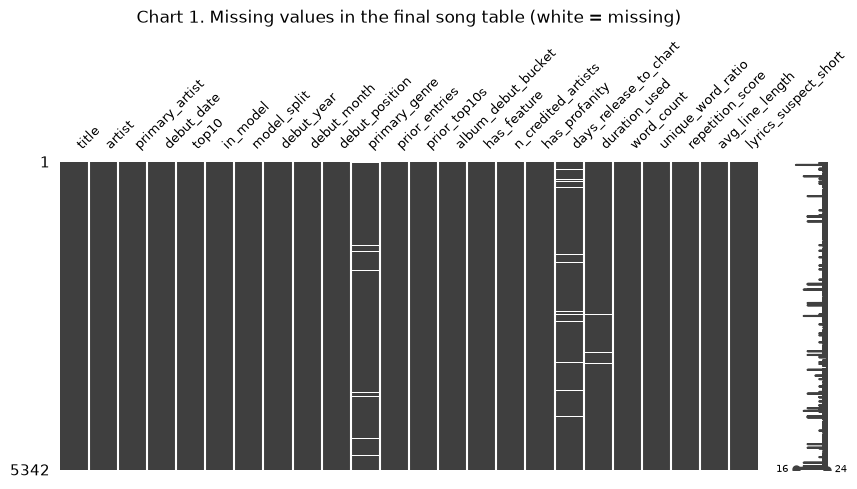

In [42]:
ax = msno.matrix(songs, figsize=(10, 4), fontsize=9)
ax.set_title('Chart 1. Missing values in the final song table (white = missing)', pad=100);

The Top 10 rate is steady at about one in ten across all nine years.

In [43]:
by_year = songs.groupby('debut_year').agg(songs=('title', 'size'), top10=('top10', 'sum'))
by_year['top10_rate'] = (by_year['top10'] / by_year['songs'] * 100).round(1)
by_year

,songs,top10,top10_rate
debut_year,,,
2018,595,67,11.3
2019,518,48,9.3
2020,674,65,9.6
2021,647,63,9.7
2022,629,77,12.2
2023,613,58,9.5
2024,617,63,10.2
2025,570,49,8.6
2026,479,29,6.1


### Summary: what we changed and why

| Column | Issue | Action | Justification |
|---|---|---|---|
| all | the archive has one row per song **per week** | Step 2: `groupby` + `agg` to one row per credit | we analyse songs, not weeks |
| `title`, `artist` | 34 songs were listed under two credits (e.g. "Kanye West" → "Ye") | Step 3: hand-checked rename list | their weeks were split and peaks understated; 5,377 → 5,342 songs, Top 10 521 → 519 |
| `artist` | one credit can name several artists | Step 4: replace separators, then `.str.split` | each artist's history must be counted; the number of artists is used in Phase 2, Q5 |
| `artist` | three names contain a separator but are one act | Step 4: protected-names list | "Lil Nas X" would be cut by " x "; Sam & Dave and Sonny & Cher would leak into Dave's and Cher's histories |
| `prior_top10s` | history could include the song itself or later songs | Step 5: count only songs that debuted strictly earlier; two checks | otherwise the predictor would leak the answer |
| `top10` | 99 songs are still on the chart | Step 6: excluded from all tests | their peak is not final |
| `primary_genre` | hundreds of detailed labels | Step 8: keyword rules + vote counts | comparable broad groups |
| `primary_genre` | ties between genres | Step 8: artist's votes break ties, otherwise "mixed" | no arbitrary choice (e.g. alphabetical) |
| `duration` | 382 album-length or placeholder durations | Step 9: MusicBrainz length; 306 repaired | needed for the cut-short check and Phase 2, Q4 |
| lyrics | some uploads are cut short | Step 9: flag the slowest 2% per genre | used for the Q4 sensitivity check |
| lyrics | section tags such as `[Chorus]` | Step 10: removed with `.str.replace` | tags are not lyrics |
| lyric measures | 32 songs have no lyrics | Step 10: left blank, not 0 | a missing song is not a zero-word song |

Two problems were fixed earlier, when the collection scripts fetched the data, so the raw
files already include the fixes: LRCLIB sometimes returned an instrumental upload for a song
with vocals (we prefer a version with lyrics), and a search by title alone could return a
different artist's song of the same name (we require the artist to match).

**So what:** after cleaning there is one row per song, every predictor uses only what was known
at debut, and every remaining gap is explained.

## 4. Phase 1 recap: what the Team Assignment found

The Team Assignment tested ten factors one at a time on the 2018-2024 songs. Here we keep its
five charts and key numbers; the full write-up is in the Team Assignment notebook.

**How to read the results (plain English).**

- **Null hypothesis (H₀):** the boring default, "this factor makes no difference." We only claim a finding when the data make that default very unlikely.
- **p-value:** how surprising the result would be if the factor truly made no difference. Below 0.05, we treat the difference as real ("reject the null").
- **Cramér's V (0 to 1):** how *big* the effect is. With thousands of songs, even tiny differences get small p-values, so V tells us whether a difference actually matters: under 0.1 is negligible, 0.1 to 0.3 is small.
- **Chi-square test:** compares Top 10 rates across groups, such as genres.
- **Mann-Whitney test:** compares a number, such as word count, between hits and non-hits without assuming a bell curve.

These two tests are the only tools here beyond the class material, so each sits in one short
helper.

In [44]:
train = songs[songs['model_split'] == 'train'].copy()
test = songs[songs['model_split'] == 'test']
print('train (2018-2024):', len(train), 'songs,', train['top10'].sum(), 'Top 10')
print('test (2025-2026):', len(test), 'songs, held out')
print('overall Top 10 rate in train:', round(train['top10'].mean() * 100, 1), '%')

train (2018-2024): 4293 songs, 441 Top 10
test (2025-2026): 950 songs, held out
overall Top 10 rate in train: 10.3 %


In [45]:
def chi_square_test(data, column, other_column='top10'):
    # Count the songs in each combination of the two columns, then test whether they are related.
    counts = pd.crosstab(data[column], data[other_column])
    chi2, p_value, dof, expected = stats.chi2_contingency(counts)
    # Cramer's V is the size of the link: 0 means none, 1 means perfect.
    cramers_v = np.sqrt(chi2 / (counts.values.sum() * (min(counts.shape) - 1)))
    print(f"chi-square = {chi2:.1f}, p = {p_value:.2e}, Cramer's V = {cramers_v:.3f}")
    return p_value, cramers_v

In [46]:
def mann_whitney_test(data, column):
    # Compare a number (e.g. word count) for Top 10 songs against all other songs.
    hits = data[data['top10'] == True][column].dropna()
    others = data[data['top10'] == False][column].dropna()
    u_stat, p_value = stats.mannwhitneyu(hits, others)
    print(f"{column}: median Top 10 = {hits.median():.3f}, median others = {others.median():.3f}, p = {p_value:.2e}")
    return hits.median(), others.median(), p_value

### 4.1 Genre

Does the Top 10 rate differ by broad genre?

In [47]:
q1 = train.groupby('primary_genre').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q1['top10_rate'] = (q1['top10_rate'] * 100).round(1)
q1 = q1.sort_values('top10_rate', ascending=False)
q1_p, q1_v = chi_square_test(train, 'primary_genre')
q1

chi-square = 89.1, p = 7.09e-16, Cramer's V = 0.146


,songs,top10_rate
primary_genre,,
pop,796,18.7
dance/electronic,106,16.0
rock/alternative,94,13.8
R&B,321,9.3
hip-hop/rap,2017,8.8
other,97,8.2
mixed,46,6.5
Latin,189,5.8
country,510,5.3


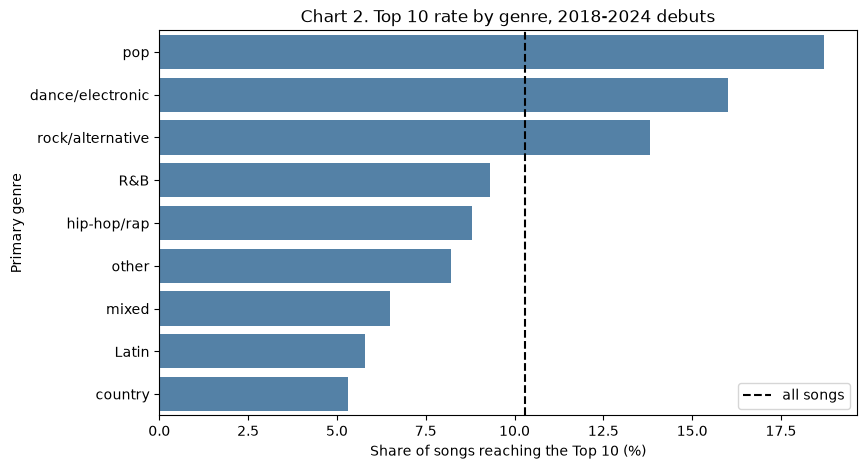

In [48]:
overall = round(train['top10'].mean() * 100, 1)

plt.figure(figsize=(9, 5))
sns.barplot(x='top10_rate', y='primary_genre', data=q1.reset_index(), color='steelblue')
plt.axvline(overall, color='k', linestyle='--', label='all songs')
plt.title('Chart 2. Top 10 rate by genre, 2018-2024 debuts')
plt.xlabel('Share of songs reaching the Top 10 (%)')
plt.ylabel('Primary genre')
plt.legend()
plt.show()

**Answer.** Yes, modestly. Pop leads at **18.7%** and country trails at **5.3%**
(p = 7.1×10⁻¹⁶, V = 0.146). Hip-hop/rap is the largest genre but converts at only 8.8%.

### 4.2 The artist's track record

Does the number of earlier Top 10 hits predict the next one?

In [49]:
def prior_bucket(count):
    if count == 0:
        return '0'
    elif count <= 4:
        return '1-4'
    elif count <= 9:
        return '5-9'
    else:
        return '10+'

In [50]:
train['prior_bucket'] = train['prior_top10s'].apply(prior_bucket)
q2 = train.groupby('prior_bucket').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q2['top10_rate'] = (q2['top10_rate'] * 100).round(1)
q2 = q2.reindex(['0', '1-4', '5-9', '10+'])
q2_p, q2_v = chi_square_test(train, 'prior_bucket')
q2

chi-square = 107.7, p = 3.44e-23, Cramer's V = 0.158


,songs,top10_rate
prior_bucket,,
0,1472,5.8
1-4,1456,8.7
5-9,458,13.3
10+,907,18.5


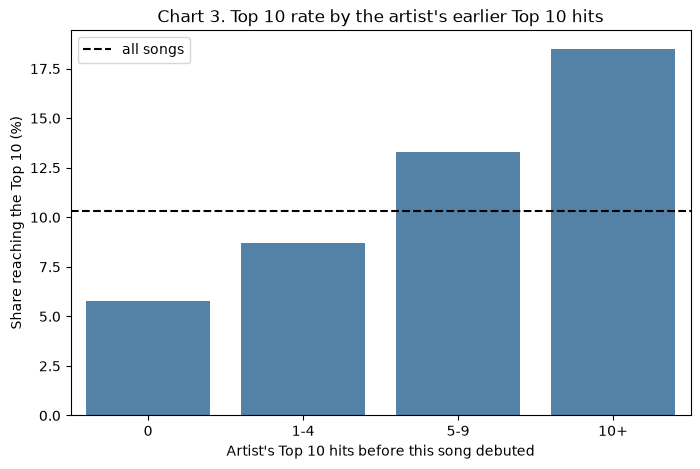

In [51]:
plt.figure(figsize=(8, 5))
sns.barplot(x='prior_bucket', y='top10_rate', data=q2.reset_index(), color='steelblue')
plt.axhline(overall, color='k', linestyle='--', label='all songs')
plt.title("Chart 3. Top 10 rate by the artist's earlier Top 10 hits")
plt.xlabel("Artist's Top 10 hits before this song debuted")
plt.ylabel('Share reaching the Top 10 (%)')
plt.legend()
plt.show()

**Answer.** Yes, and it is the strongest single factor: **5.8%** for artists with no earlier
Top 10, rising steadily to **18.5%** for artists with ten or more (p = 3.4×10⁻²³, V = 0.158).

### 4.3 Album drops

Does releasing many songs in the same week change each song's chance?

In [52]:
q3 = train.groupby('album_debut_bucket').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
q3['top10_rate'] = (q3['top10_rate'] * 100).round(1)
q3 = q3.reindex(['1', '2-4', '5-9', '10+'])
q3_p, q3_v = chi_square_test(train, 'album_debut_bucket')
q3

chi-square = 44.5, p = 1.16e-09, Cramer's V = 0.102


,songs,top10_rate
album_debut_bucket,,
1,2123,11.6
2-4,366,6.3
5-9,425,2.1
10+,1379,11.8


In [53]:
def artist_group(prior_top10s):
    if prior_top10s > 0:
        return 'Established (1+ earlier Top 10)'
    else:
        return 'Newcomer (no earlier Top 10)'

train['artist_group'] = train['prior_top10s'].apply(artist_group)
q3_split = train.groupby(['album_debut_bucket', 'artist_group']).agg(
    songs=('top10', 'size'), top10_rate=('top10', 'mean')).reset_index()
q3_split['top10_rate'] = (q3_split['top10_rate'] * 100).round(1)
q3_split

,album_debut_bucket,artist_group,songs,top10_rate
0,1,Established (1+ earlier Top 10),1011,17.0
1,1,Newcomer (no earlier Top 10),1112,6.7
2,10+,Established (1+ earlier Top 10),1248,12.7
3,10+,Newcomer (no earlier Top 10),131,3.1
4,2-4,Established (1+ earlier Top 10),247,7.3
5,2-4,Newcomer (no earlier Top 10),119,4.2
6,5-9,Established (1+ earlier Top 10),315,2.2
7,5-9,Newcomer (no earlier Top 10),110,1.8


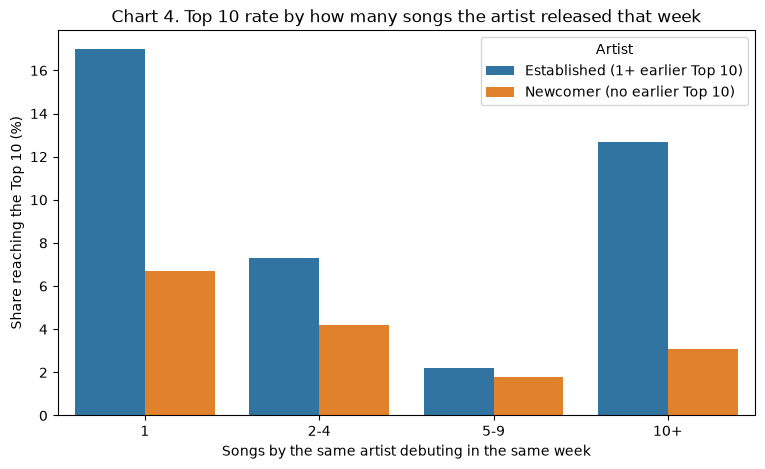

In [54]:
plt.figure(figsize=(9, 5))
sns.barplot(x='album_debut_bucket', y='top10_rate', hue='artist_group', data=q3_split,
            order=['1', '2-4', '5-9', '10+'])
plt.title('Chart 4. Top 10 rate by how many songs the artist released that week')
plt.xlabel('Songs by the same artist debuting in the same week')
plt.ylabel('Share reaching the Top 10 (%)')
plt.legend(title='Artist')
plt.show()

**Answer.** Yes (p = 1.2×10⁻⁹, V = 0.102). Songs released alone reach the Top 10 at
**11.6%**; songs in a 5-9 song drop at **2.1%**. The rise at 10+ songs (11.8%) comes only from
established artists. This left one question open, which Phase 2 Q2 answers: is the drop
penalty real, or do drops just come from different artists?

### 4.4 Lyric style

Do the lyrics of Top 10 songs differ on four simple measures?

In [55]:
lyric_measures = ['word_count', 'unique_word_ratio', 'repetition_score', 'avg_line_length']
q4_results = []
for measure in lyric_measures:
    q4_results.append(mann_whitney_test(train, measure))

word_count: median Top 10 = 433.000, median others = 422.000, p = 7.31e-02
unique_word_ratio: median Top 10 = 0.348, median others = 0.361, p = 9.51e-05
repetition_score: median Top 10 = 0.433, median others = 0.419, p = 1.69e-01
avg_line_length: median Top 10 = 7.847, median others = 7.865, p = 2.01e-01


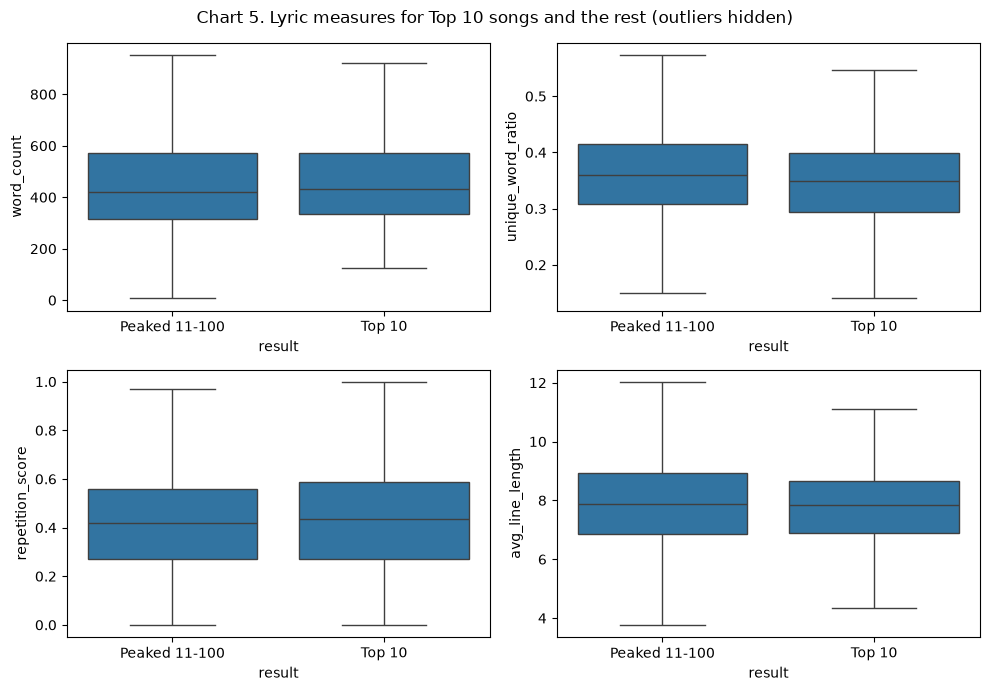

In [56]:
train['result'] = train['top10'].map({True: 'Top 10', False: 'Peaked 11-100'})

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
sns.boxplot(x='result', y='word_count', data=train, showfliers=False, ax=axes[0, 0])
sns.boxplot(x='result', y='unique_word_ratio', data=train, showfliers=False, ax=axes[0, 1])
sns.boxplot(x='result', y='repetition_score', data=train, showfliers=False, ax=axes[1, 0])
sns.boxplot(x='result', y='avg_line_length', data=train, showfliers=False, ax=axes[1, 1])
plt.suptitle('Chart 5. Lyric measures for Top 10 songs and the rest (outliers hidden)')
plt.tight_layout()
plt.show()

In [57]:
# Sensitivity check: leave out songs whose lyrics may be cut short, then test again.
complete = train[train['lyrics_suspect_short'] == False]
print('songs left out:', len(train) - len(complete))
for measure in lyric_measures:
    mann_whitney_test(complete, measure)

songs left out: 84
word_count: median Top 10 = 435.000, median others = 426.000, p = 1.61e-01
unique_word_ratio: median Top 10 = 0.348, median others = 0.360, p = 2.62e-04
repetition_score: median Top 10 = 0.432, median others = 0.418, p = 1.81e-01
avg_line_length: median Top 10 = 7.849, median others = 7.898, p = 1.22e-01


**Answer.** Barely. Only vocabulary diversity differs (unique word ratio 0.348 vs 0.361,
p = 9.5×10⁻⁵); word count, repetition and line length do not. Leaving out lyrics that may be
cut short gives the same answer.

### 4.5 Release month

Is there a best month to release a hit, or is that an album-schedule effect?

In [58]:
q5_all = train.groupby('debut_month').agg(top10_rate=('top10', 'mean'))
q5_all['top10_rate'] = (q5_all['top10_rate'] * 100).round(1)
print('All songs:')
q5_all_p, q5_all_v = chi_square_test(train, 'debut_month')

small_drops = train[train['album_debut_bucket'].isin(['1', '2-4'])]
q5_small = small_drops.groupby('debut_month').agg(top10_rate=('top10', 'mean'))
q5_small['top10_rate'] = (q5_small['top10_rate'] * 100).round(1)
print('Without drops of 5+ songs:')
q5_small_p, q5_small_v = chi_square_test(small_drops, 'debut_month')

pd.DataFrame({'all songs': q5_all['top10_rate'], 'without drops of 5+': q5_small['top10_rate']}).T

All songs:
chi-square = 25.0, p = 9.15e-03, Cramer's V = 0.076
Without drops of 5+ songs:
chi-square = 5.5, p = 9.06e-01, Cramer's V = 0.047


debut_month,1,2,3,4,5,6,7,8,9,10,11,12
all songs,9.0,8.7,7.0,10.8,15.1,9.7,8.7,9.4,9.7,9.9,14.8,9.6
without drops of 5+,10.3,9.8,8.9,11.3,14.3,11.9,9.3,11.5,9.2,12.0,11.5,9.7


In [59]:
# The biggest same-artist release weeks in the training years.
drop_weeks = train.groupby(['primary_artist', 'debut_date']).agg(
    songs=('top10', 'size'), top10=('top10', 'sum')).reset_index()
drop_weeks.sort_values('songs', ascending=False).head(3)

,primary_artist,debut_date,songs,top10
2121,taylor swift,2024-05-04,31,10
1603,morgan wallen,2023-03-18,27,1
2111,taylor swift,2021-11-27,26,1


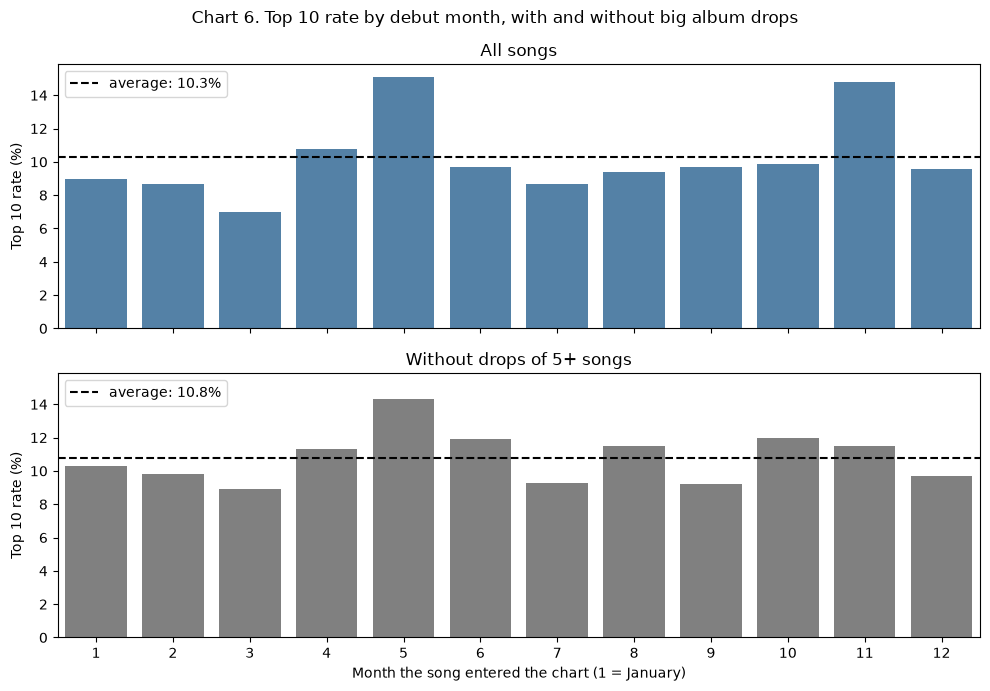

In [60]:
# Each panel gets its own average: the songs without big drops average 10.8%, not 10.3%.
small_average = round(small_drops['top10'].mean() * 100, 1)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)
sns.barplot(x='debut_month', y='top10_rate', data=q5_all.reset_index(), color='steelblue', ax=axes[0])
axes[0].axhline(overall, color='k', linestyle='--', label='average: ' + str(overall) + '%')
axes[0].set_title('All songs')
sns.barplot(x='debut_month', y='top10_rate', data=q5_small.reset_index(), color='gray', ax=axes[1])
axes[1].axhline(small_average, color='k', linestyle='--', label='average: ' + str(small_average) + '%')
axes[1].set_title('Without drops of 5+ songs')
for ax in axes:
    ax.set_ylabel('Top 10 rate (%)')
    ax.legend(loc='upper left')
axes[1].set_xlabel('Month the song entered the chart (1 = January)')
plt.suptitle('Chart 6. Top 10 rate by debut month, with and without big album drops')
plt.tight_layout()
plt.show()

**Answer.** No reliable month. May (15.1%) and November (14.8%) look strong (p = 0.0092),
partly because of superstar album weeks such as Taylor Swift's 31-song week in May 2024.
Without drops of five or more songs the month effect disappears (p = 0.906).

### 4.6 The other five questions

The remaining Team Assignment questions, retested in one cell:

In [61]:
def debut_bucket(position):
    if position <= 10:
        return '1-10'
    elif position <= 25:
        return '11-25'
    elif position <= 50:
        return '26-50'
    elif position <= 75:
        return '51-75'
    else:
        return '76-100'

In [62]:
print('Q6, featured artist:')
q6_p, q6_v = chi_square_test(train, 'has_feature')
with_lyrics = train.dropna(subset=['has_profanity'])
print('Q7, profanity:')
q7_p, q7_v = chi_square_test(with_lyrics, 'has_profanity')
print('Q8, days from release to chart:')
q8_hits, q8_others, q8_p = mann_whitney_test(train, 'days_release_to_chart')
hits = train[train['top10'] == True].dropna(subset=['primary_genre'])
print('Q9, genre mix of Top 10 songs by year:')
q9_p, q9_v = chi_square_test(hits, 'debut_year', 'primary_genre')
train['debut_bucket'] = train['debut_position'].apply(debut_bucket)
outside = train[train['debut_position'] > 10]
print('Q10, debut position (songs that debuted outside the Top 10 only):')
q10_p, q10_v = chi_square_test(outside, 'debut_bucket')

Q6, featured artist:
chi-square = 0.5, p = 4.94e-01, Cramer's V = 0.010
Q7, profanity:
chi-square = 0.1, p = 7.36e-01, Cramer's V = 0.005
Q8, days from release to chart:
days_release_to_chart: median Top 10 = 15.000, median others = 15.000, p = 4.96e-05
Q9, genre mix of Top 10 songs by year:
chi-square = 82.9, p = 1.31e-03, Cramer's V = 0.178
Q10, debut position (songs that debuted outside the Top 10 only):
chi-square = 23.7, p = 2.86e-05, Cramer's V = 0.077


| Question | Top 10 rate or median | Result |
|---|---|---|
| Q6. Featured artist | 9.6% with vs 10.4% without | no effect (p = 0.494) |
| Q7. Explicit lyrics | 10.1% vs 10.5% | no effect (p = 0.736) |
| Q8. Days from release to chart | median 15 days for both; slow-charting songs are rarely hits | significant (p = 5.0×10⁻⁵) but small |
| Q9. Genre mix of Top 10 hits over time | hip-hop/rap 56.7% (2018) → 36.5% (2024); country 0% → 11.1% | changed (p = 0.0013) |
| Q10. Debut position | debuting at 1-10 *is* a Top 10, so we test only songs that debuted lower: 6.7% (11-25) → 2.6% (76-100) | significant but weak (V = 0.077) |

**Phase 1 takeaway:** *who* releases a song and *how* it is released matter far more than what
the lyrics look like. Q10 also taught us to check every feature against the definition of the
target, which is the leakage rule our Phase 2 model follows.

## 5. Phase 2: deeper questions

Phase 1 looked at one factor at a time. Phase 2 asks five deeper questions:

1. Can a model combine the debut-week factors and spot hits in years it has never seen?
2. Is the album-drop penalty real when we compare songs **by the same artist**?
3. How do hits move on the chart week by week, and has that changed?
4. Are songs getting shorter, and do hits follow?
5. Are collaborations becoming more common, and do they help?

Phase 2 uses every song with a final peak, including the 2025-2026 test songs.

In [63]:
# Phase 2 uses every song with a final peak: 2018-2024 (train) and 2025-2026 (test).
finished = songs[songs['in_model'] == True].copy()
print('songs with a final peak:', len(finished), '| Top 10:', finished['top10'].sum())
print('still on the chart (left out):', len(songs) - len(finished),
      '| of those already in the Top 10:', songs[songs['in_model'] == False]['top10'].sum())
print(finished.groupby('model_split')['top10'].agg(['size', 'sum', 'mean']).round(3))

songs with a final peak: 5243 | Top 10: 497
still on the chart (left out): 99 | of those already in the Top 10: 22
             size  sum   mean
model_split                  
test          950   56  0.059
train        4293  441  0.103


The test years have a lower Top 10 rate (5.9% vs 10.3%). Part of the reason is in the second
line: hits stay on the chart longer, so 22 recent hits are still charting and left out. This
makes the test harder, not easier.

### 5.1 Can we predict a Top 10 hit in its debut week?

**Question.** Using only what is known in a song's first week, can a model pick out the songs
that will reach the Top 10, and does it beat a simple rule based on the artist's history?

**Method.** We follow the steps from the class classification notebook: build `X` and `y`,
turn categories into dummy columns with `pd.get_dummies`, fit a `LogisticRegression`, and
predict on the test set. We train on 2018-2024 and test once on 2025-2026. This is a split by
time, not a random one, so the model is judged on years it has never seen.

We compare two models:

- **Baseline:** the artist's history only (earlier Top 10 hits and earlier chart entries).
- **Full model:** the baseline plus genre, album-drop size, number of credited artists,
  featured artist, profanity, song length, days from release to chart, and four lyric measures.

**Leakage rule.** Every feature must be known in the debut week, so `debut_position`,
`peak_position` and `weeks_on_chart` are not allowed. The cell below checks this.

In [64]:
# Only facts known in the song's debut week.
BASELINE_FEATURES = ['prior_top10s', 'prior_entries']
FULL_FEATURES = BASELINE_FEATURES + ['primary_genre', 'album_debut_bucket', 'n_credited_artists',
                                     'has_feature', 'has_profanity', 'duration_used', 'days_release_to_chart',
                                     'word_count', 'unique_word_ratio', 'repetition_score', 'avg_line_length']

# Leakage rule: nothing measured after the debut week may be a feature.
for column in ['debut_position', 'peak_position', 'weeks_on_chart']:
    assert column not in FULL_FEATURES
print('features before dummies:', len(FULL_FEATURES))

features before dummies: 13


One dummy column per category is dropped, as in class: genres are compared with Latin, and
drop sizes with songs released alone.

In [65]:
X = finished[FULL_FEATURES].copy()
X = pd.get_dummies(X, columns=['primary_genre', 'album_debut_bucket'], drop_first=True)
X = X.astype(float)
y = finished['top10']

Xtrain = X[finished['model_split'] == 'train']
Xtest = X[finished['model_split'] == 'test']
ytrain = y[finished['model_split'] == 'train']
ytest = y[finished['model_split'] == 'test']
print('Xtrain:', Xtrain.shape, '| Xtest:', Xtest.shape)

Xtrain: (4293, 22) | Xtest: (950, 22)


Missing values are filled with the **training set's** medians, and features are standardised
with the **training set's** means and standard deviations; the test set reuses those same
numbers, so nothing about the test years leaks into the model.

In [66]:
# Medians, means and standard deviations come from the TRAINING songs only,
# and the same numbers are applied to the test songs.
train_medians = Xtrain.median()
Xtrain = Xtrain.fillna(train_medians)
Xtest = Xtest.fillna(train_medians)

train_means = Xtrain.mean()
train_stds = Xtrain.std()
Xtrain = (Xtrain - train_means) / train_stds
Xtest = (Xtest - train_means) / train_stds
Xtrain.head(3).round(2)

,prior_top10s,prior_entries,n_credited_artists,has_feature,has_profanity,duration_used,days_release_to_chart,word_count,unique_word_ratio,repetition_score,...,primary_genre_country,primary_genre_dance/electronic,primary_genre_hip-hop/rap,primary_genre_mixed,primary_genre_other,primary_genre_pop,primary_genre_rock/alternative,album_debut_bucket_10+,album_debut_bucket_2-4,album_debut_bucket_5-9
1,0.03,-0.13,-0.65,-0.51,-1.08,-0.41,-0.16,-0.66,-0.20,0.84,...,2.72,-0.16,-0.94,-0.1,-0.15,-0.48,-0.15,1.45,-0.31,-0.33
2,-0.56,-0.71,-0.65,-0.51,-1.08,0.46,-0.03,-0.50,-0.53,0.62,...,2.72,-0.16,-0.94,-0.1,-0.15,-0.48,-0.15,-0.69,-0.31,-0.33
3,1.79,1.19,-0.65,-0.51,-1.08,0.57,-0.16,-0.24,0.16,0.48,...,-0.37,-0.16,-0.94,-0.1,-0.15,2.10,-0.15,1.45,-0.31,-0.33


In [67]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, confusion_matrix

baseline = LogisticRegression(solver='liblinear')     # artist history only
baseline.fit(Xtrain[BASELINE_FEATURES], ytrain)
y_baseline = baseline.predict(Xtest[BASELINE_FEATURES])

model = LogisticRegression(solver='liblinear')        # all debut-week features
model.fit(Xtrain, ytrain)
y_model = model.predict(Xtest)

**Why precision and recall, not accuracy?** A model that always says "not a hit" is 94%
accurate on the test songs and completely useless. **Precision** answers "of the songs the
model flagged, how many became hits?" **Recall** answers "of the real hits, how many did the
model catch?"

In [68]:
scores = pd.DataFrame({
    'model': ['Baseline (artist history)', 'Full model'],
    'precision': [precision_score(ytest, y_baseline), precision_score(ytest, y_model)],
    'recall': [recall_score(ytest, y_baseline), recall_score(ytest, y_model)],
    'songs flagged as hits': [y_baseline.sum(), y_model.sum()]})
scores['precision'] = (scores['precision'] * 100).round(1)
scores['recall'] = (scores['recall'] * 100).round(1)

print('test songs:', len(ytest), '| real Top 10 hits:', ytest.sum())
print('accuracy of always saying "not a hit":', round((1 - ytest.mean()) * 100, 1), '%')
scores

test songs: 950 | real Top 10 hits: 56
accuracy of always saying "not a hit": 94.1 %


,model,precision,recall,songs flagged as hits
0,Baseline (artist history),19.6,16.1,46
1,Full model,42.9,26.8,35


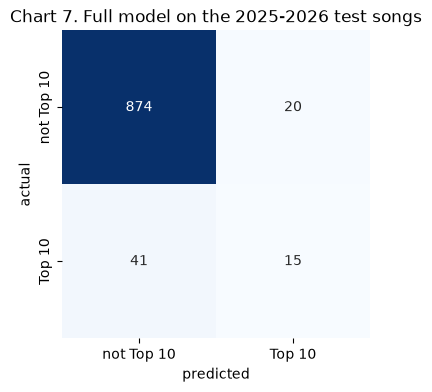

In [69]:
mat = confusion_matrix(ytest, y_model)

plt.figure(figsize=(5, 4))
sns.heatmap(mat, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=['not Top 10', 'Top 10'], yticklabels=['not Top 10', 'Top 10'])
plt.title('Chart 7. Full model on the 2025-2026 test songs')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()

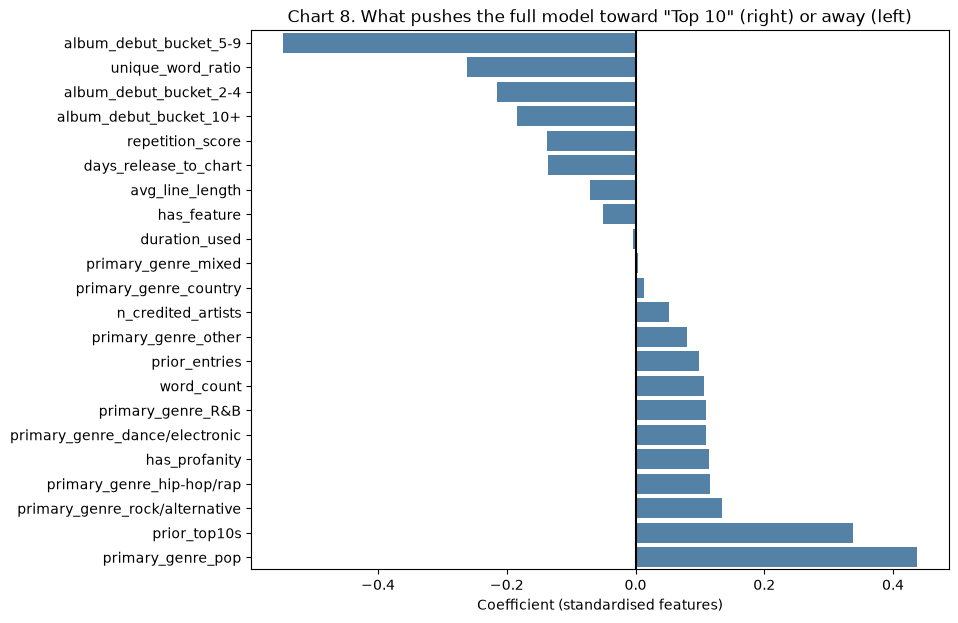

In [70]:
# Features are standardised, so each coefficient is the effect of a one-standard-deviation change.
coefficients = pd.DataFrame({'feature': Xtrain.columns, 'coefficient': model.coef_[0]})
coefficients = coefficients.sort_values('coefficient')

plt.figure(figsize=(9, 7))
sns.barplot(x='coefficient', y='feature', data=coefficients, color='steelblue')
plt.axvline(0, color='k')
plt.title('Chart 8. What pushes the full model toward "Top 10" (right) or away (left)')
plt.xlabel('Coefficient (standardised features)')
plt.ylabel('')
plt.show()

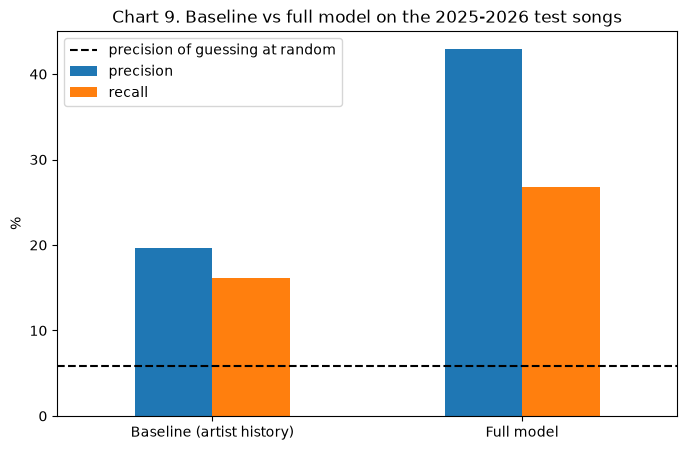

In [71]:
scores.set_index('model')[['precision', 'recall']].plot(kind='bar', figsize=(8, 5), rot=0)
plt.axhline(ytest.mean() * 100, color='k', linestyle='--', label='precision of guessing at random')
plt.title('Chart 9. Baseline vs full model on the 2025-2026 test songs')
plt.xlabel('')
plt.ylabel('%')
plt.legend()
plt.show()

**Answer.** Yes, the full model clearly beats the baseline on both measures.

- **Precision 42.9% vs 19.6%.** The full model flagged 35 test songs, and 15 of them became
  Top 10 hits. Picking songs at random would give 5.9%.
- **Recall 26.8% vs 16.1%.** It caught 15 of the 56 real hits; the baseline caught 9.
- **What drives it (Chart 8).** Being pop (+0.44) and the artist's earlier Top 10s (+0.34)
  push toward a hit. Being in a 5-9 song drop pushes away most strongly (−0.55). A larger
  vocabulary (unique word ratio, −0.26) also pushes away, which matches Phase 1. Song length
  adds almost nothing once the other features are known.

**Caveat.** The test set has only 56 hits, so one or two songs more or less move each measure
by a few points. The model uses the default cut-off (probability above 0.5); a label that
prefers to catch more hits could lower it and accept more false alarms.

**So what:** a model built only from debut-week facts finds hits at about seven times the
random rate. It is useful for ranking songs for marketing attention, not for promising a hit.
This meets our success criterion: it beats the artist-history baseline on precision and recall.

### 5.2 The album-drop penalty within the same artist

**Question.** Phase 1 found that songs in big album drops rarely reach the Top 10. But drops
come from particular artists, so the penalty could be about *who* drops albums. Here we hold
the artist fixed: for every artist who released songs **both** on their own **and** in a drop
of five or more songs in 2018-2024, we compare the two kinds.

In [72]:
def release_type(bucket):
    if bucket == '1':
        return 'alone'
    elif bucket == '5-9' or bucket == '10+':
        return 'drop of 5+'
    else:
        return 'other'

train['release_type'] = train['album_debut_bucket'].apply(release_type)
compare = train[train['release_type'] != 'other'].copy()
compare['types_used'] = compare.groupby('primary_artist')['release_type'].transform('nunique')
both = compare[compare['types_used'] == 2]
print('artists with songs of both kinds:', both['primary_artist'].nunique(), '| songs:', len(both))

artists with songs of both kinds: 63 | songs: 2273


For each artist, we compute the Top 10 rate of each kind of release and note which one did better.

In [73]:
per_artist = both.groupby(['primary_artist', 'release_type'])['top10'].mean().unstack() * 100

def compare_rates(row):
    if row['alone'] > row['drop of 5+']:
        return 'better alone'
    elif row['alone'] < row['drop of 5+']:
        return 'better in drops'
    else:
        return 'tie'

per_artist['verdict'] = per_artist.apply(compare_rates, axis=1)
print(per_artist['verdict'].value_counts())
per_artist.loc[['drake', 'taylor swift', 'morgan wallen']].round(1)

verdict
better alone       38
tie                17
better in drops     8
Name: count, dtype: int64


release_type,alone,drop of 5+,verdict
primary_artist,,,
drake,70.0,26.5,better alone
taylor swift,17.6,20.2,better in drops
morgan wallen,54.5,5.0,better alone


In [74]:
ties = per_artist[per_artist['verdict'] == 'tie']
print('ties where both rates are 0%:', (ties['alone'] == 0).sum(), 'of', len(ties))
print('pooled songs of these artists:')
album_p, album_v = chi_square_test(both, 'release_type')
(both.groupby('release_type')['top10'].mean() * 100).round(1)

ties where both rates are 0%: 17 of 17
pooled songs of these artists:
chi-square = 59.5, p = 1.24e-14, Cramer's V = 0.162


release_type
alone         22.6
drop of 5+     9.7
Name: top10, dtype: float64

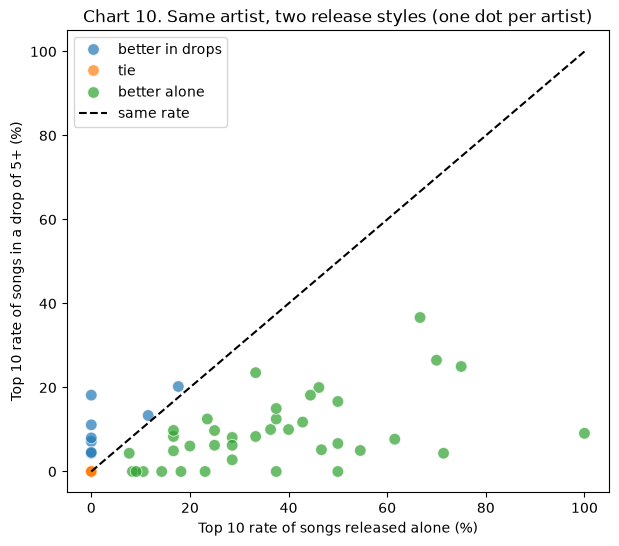

In [75]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x='alone', y='drop of 5+', hue='verdict', data=per_artist, s=70, alpha=0.7)
plt.plot([0, 100], [0, 100], color='k', linestyle='--', label='same rate')
plt.title('Chart 10. Same artist, two release styles (one dot per artist)')
plt.xlabel('Top 10 rate of songs released alone (%)')
plt.ylabel('Top 10 rate of songs in a drop of 5+ (%)')
plt.legend()
plt.show()

**Answer.** The penalty is real: it holds within the same artist.

- **Artist by artist (the fair comparison).** Of 63 artists, **38 did better with songs
  released alone** and only **8 did better in drops**. All 17 ties are artists who never
  reached the Top 10 either way. Drake reached it with 70.0% of his solo releases but 26.5% of
  his album-drop songs; Morgan Wallen 54.5% vs 5.0%. Taylor Swift is one of the few exceptions
  (17.6% vs 20.2%).
- **Pooled songs (supporting evidence).** Across these artists' songs, 22.6% of solo releases
  reached the Top 10 against 9.7% of album-drop songs (p = 1.2×10⁻¹⁴, V = 0.162).

**Caveat.** A song released on its own is usually the lead single, the track the label already
believes is strongest. Part of the gap is song choice, not only release format. Several
"better in drops" artists had very few solo songs, so their 0% rates are fragile.

**So what:** even for the same artist, a song released alone is far more likely to reach the
Top 10. Lead singles should get their own release week.

### 5.3 Chart trajectories: when do hits peak?

**Question.** How many weeks does a Top 10 hit take to reach its peak, has "debut at the
peak" become more common, and do recent hits fade faster? We work from the weekly chart rows,
as in the class time-series notebook.

In [76]:
# Every chart week of every finished Top 10 song.
hits = finished[finished['top10'] == True][['title', 'artist', 'debut_date', 'debut_year']]
hit_weeks = pd.merge(weekly, hits, on=['title', 'artist'], how='inner')

# The first week each song reached its best position.
best = hit_weeks.groupby(['title', 'artist'])['position'].transform('min')
peak_weeks = hit_weeks[hit_weeks['position'] == best]
peak_dates = peak_weeks.groupby(['title', 'artist']).agg(peak_date=('chart_date', 'min')).reset_index()

hits = pd.merge(hits, peak_dates, on=['title', 'artist'], how='left', validate='one_to_one')
hits['weeks_to_peak'] = (hits['peak_date'] - hits['debut_date']).dt.days // 7
hits['weeks_to_peak'].describe().round(1)

count    497.0
mean       7.6
std       20.0
min        0.0
25%        0.0
50%        0.0
75%       11.0
max      261.0
Name: weeks_to_peak, dtype: float64

peaked in the debut week: 58.4 % | within 4 weeks: 67.8 %
hits that took more than 30 weeks to peak: 31


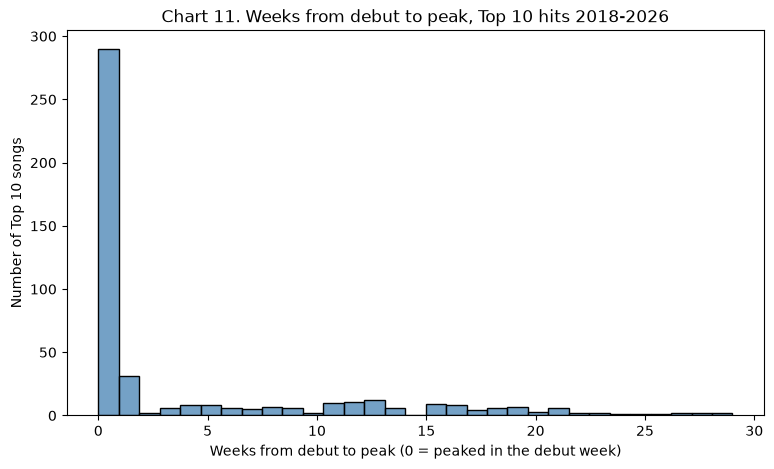

In [77]:
print('peaked in the debut week:', round((hits['weeks_to_peak'] == 0).mean() * 100, 1), '%',
      '| within 4 weeks:', round((hits['weeks_to_peak'] <= 4).mean() * 100, 1), '%')
print('hits that took more than 30 weeks to peak:', (hits['weeks_to_peak'] > 30).sum())

plt.figure(figsize=(9, 5))
sns.histplot(hits[hits['weeks_to_peak'] <= 30]['weeks_to_peak'], bins=31, color='steelblue')
plt.title('Chart 11. Weeks from debut to peak, Top 10 hits 2018-2026')
plt.xlabel('Weeks from debut to peak (0 = peaked in the debut week)')
plt.ylabel('Number of Top 10 songs')
plt.show()

The 31 slow climbers include holiday songs that peak in a later December (The Ronettes'
"Sleigh Ride" peaked 261 weeks after its 2018 debut) and sleeper hits such as Taylor Swift's
"Cruel Summer" (216 weeks) and Glass Animals' "Heat Waves" (60 weeks).

Next, the share of each year's hits that peaked in their debut week. We group by year with
`resample('YE')` on a date index:

In [78]:
# Share of each year's hits that peaked in their debut week. 2026 is left out: its hits are still young.
hits['debut_at_peak'] = hits['weeks_to_peak'] == 0
complete_years = hits[hits['debut_year'] <= 2025]
at_peak_by_year = complete_years.set_index('debut_date')['debut_at_peak'].resample('YE').mean() * 100
at_peak_by_year.index = at_peak_by_year.index.year
at_peak_by_year.round(1)

debut_date
2018    46.3
2019    33.3
2020    63.1
2021    60.3
2022    63.6
2023    62.1
2024    68.3
2025    57.8
Name: debut_at_peak, dtype: float64

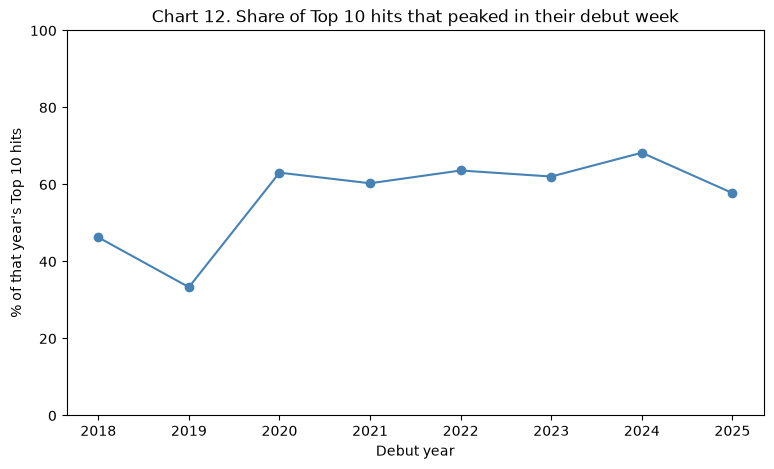

In [79]:
plt.figure(figsize=(9, 5))
at_peak_by_year.plot(style='o-', color='steelblue')
plt.title('Chart 12. Share of Top 10 hits that peaked in their debut week')
plt.xlabel('Debut year')
plt.ylabel('% of that year\'s Top 10 hits')
plt.ylim(0, 100)
plt.show()

Finally, the typical path of a hit: the median chart position in each week after debut, for
older and newer hits.

In [80]:
def era(year):
    if year <= 2021:
        return '2018-2021'
    else:
        return '2022-2025'

hit_weeks['week_number'] = (hit_weeks['chart_date'] - hit_weeks['debut_date']).dt.days // 7
path = hit_weeks[(hit_weeks['debut_year'] <= 2025) & (hit_weeks['week_number'] <= 30)].copy()
path['era'] = path['debut_year'].apply(era)
path = path.groupby(['era', 'week_number']).agg(median_position=('position', 'median'),
                                                songs_still_charting=('title', 'size')).reset_index()
path[path['week_number'].isin([0, 10, 20, 30])]

,era,week_number,median_position,songs_still_charting
0,2018-2021,0,8.0,243
10,2018-2021,10,14.0,187
20,2018-2021,20,13.0,135
30,2018-2021,30,18.0,85
31,2022-2025,0,7.0,243
41,2022-2025,10,22.5,172
51,2022-2025,20,18.0,114
61,2022-2025,30,21.0,72


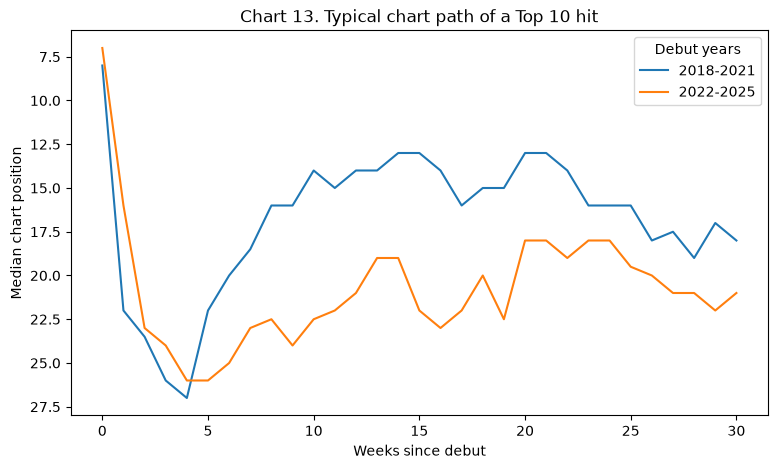

In [81]:
plt.figure(figsize=(9, 5))
sns.lineplot(x='week_number', y='median_position', hue='era', data=path)
plt.gca().invert_yaxis()                       # position 1 at the top
plt.title('Chart 13. Typical chart path of a Top 10 hit')
plt.xlabel('Weeks since debut')
plt.ylabel('Median chart position')
plt.legend(title='Debut years')
plt.show()

*Caveat: later weeks only include songs still on the chart, so the right side of Chart 13
describes the hits that lasted, not every hit.*

**Answer.**

- **Most hits peak immediately.** The median Top 10 hit peaks in its debut week: 58.4% do, and
  two-thirds peak within four weeks (Chart 11).
- **This has become more common.** 46.3% of 2018 hits peaked in their debut week, 60-68% in
  2020-2024, and 57.8% in 2025 (Chart 12). 2019 (33.3%) is the exception.
- **Recent hits fade faster.** Both groups debut around position 7-8 and fall to the mid-20s
  within four weeks. Hits from 2018-2021 then climbed back to about 13-14 by weeks 10-20; hits
  from 2022-2025 stayed around 18-24 (Chart 13).

**So what:** a hit's fate is usually settled in release week, and recent hits get less of a
second wind. Marketing that arrives after the debut is mostly too late, which is also why a
debut-week model (5.1) is the right tool.

### 5.4 Are songs getting shorter?

**Question.** Streaming pays per play, which is often said to push songs shorter. Is that
visible on the Hot 100, and are Top 10 hits shorter than other songs?

In [82]:
# 2026 is left out of the yearly views: only 11 of its finished songs are Top 10 hits.
finished['minutes'] = finished['duration_used'] / 60
complete_years = finished[finished['debut_year'] <= 2025]
length_by_year = complete_years.groupby(['debut_year', 'top10'])['minutes'].median().unstack().round(2)
length_by_year.columns = ['others', 'Top 10']
length_by_year

,others,Top 10
debut_year,,
2018,3.38,3.58
2019,3.25,3.18
2020,3.20,3.35
2021,3.30,3.48
2022,3.17,3.31
2023,3.25,3.33
2024,3.22,3.53
2025,3.17,3.32


In [83]:
train['minutes'] = train['duration_used'] / 60
length_p = mann_whitney_test(train, 'minutes')[2]
print('median length, all songs, 2018:', round(finished[finished['debut_year'] == 2018]['minutes'].median(), 2),
      '| 2025:', round(finished[finished['debut_year'] == 2025]['minutes'].median(), 2))

minutes: median Top 10 = 3.383, median others = 3.250, p = 2.85e-04
median length, all songs, 2018: 3.4 | 2025: 3.18


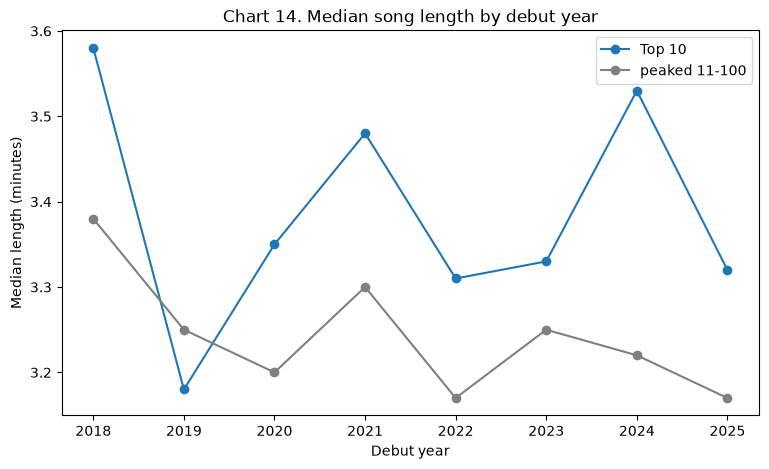

In [84]:
plt.figure(figsize=(9, 5))
plt.plot(length_by_year.index, length_by_year['Top 10'], 'o-', label='Top 10')
plt.plot(length_by_year.index, length_by_year['others'], 'o-', color='gray', label='peaked 11-100')
plt.title('Chart 14. Median song length by debut year')
plt.xlabel('Debut year')
plt.ylabel('Median length (minutes)')
plt.legend()
plt.show()

**Answer.** Songs on the chart are getting a little shorter, but hits are not.

- The median song fell from **3.40 minutes** in 2018 to **3.18** in 2025, about 13 seconds.
- Top 10 hits were *longer* than other songs in 7 of the 8 years. In 2018-2024 the medians were
  3.38 vs 3.25 minutes (p = 2.9×10⁻⁴).

**Caveat.** Length comes from LRCLIB or MusicBrainz and may be the album version rather than a
radio edit. In the model (5.1), length adds almost nothing once genre and artist are known, so
the gap is mostly *which* songs become hits (pop and country run longer than rap), not length itself.

**So what:** cutting a song short is not a route to the Top 10.

### 5.5 Collaborations over time

**Question.** Are songs credited to two or more artists (featuring, "&", "x", and so on)
becoming more common, and do they reach the Top 10 more often? Phase 1 only looked at the word
"Featuring"; here we count every credited artist.

In [85]:
finished['collaboration'] = finished['n_credited_artists'] >= 2
train['collaboration'] = train['n_credited_artists'] >= 2

complete_years = finished[finished['debut_year'] <= 2025]
share_all = complete_years.groupby('debut_year')['collaboration'].mean() * 100
share_hits = complete_years[complete_years['top10'] == True].groupby('debut_year')['collaboration'].mean() * 100
collab_by_year = pd.DataFrame({'all songs': share_all, 'Top 10 hits': share_hits}).round(1)
collab_by_year.T

debut_year,2018,2019,2020,2021,2022,2023,2024,2025
all songs,40.5,39.2,38.3,42.0,36.1,33.9,36.1,32.0
Top 10 hits,44.8,31.2,53.8,36.5,36.4,32.8,31.7,22.2


In [86]:
collab_rate = train.groupby('collaboration').agg(songs=('top10', 'size'), top10_rate=('top10', 'mean'))
collab_rate['top10_rate'] = (collab_rate['top10_rate'] * 100).round(1)
collab_p, collab_v = chi_square_test(train, 'collaboration')
collab_rate

chi-square = 0.0, p = 8.48e-01, Cramer's V = 0.003


,songs,top10_rate
collaboration,,
False,2661,10.2
True,1632,10.4


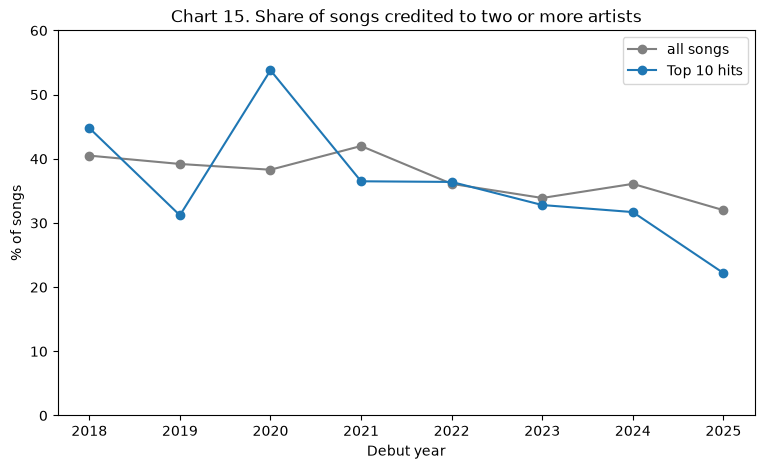

In [87]:
plt.figure(figsize=(9, 5))
plt.plot(collab_by_year.index, collab_by_year['all songs'], 'o-', color='gray', label='all songs')
plt.plot(collab_by_year.index, collab_by_year['Top 10 hits'], 'o-', label='Top 10 hits')
plt.title('Chart 15. Share of songs credited to two or more artists')
plt.xlabel('Debut year')
plt.ylabel('% of songs')
plt.ylim(0, 60)
plt.legend()
plt.show()

**Answer.** Collaborations are becoming *less* common, and they do not help.

- **Trend.** 40.5% of 2018 songs were collaborations; by 2025 it was 32.0%. Among Top 10 hits the share jumps around from year to
  year and was lowest in 2025 (22.2%).
- **Effect.** Collaborations reach the Top 10 at **10.4%**, solo songs at **10.2%**
  (p = 0.848, V = 0.003): no difference.

**Caveat.** Each year has only 45-77 hits, so the hits line in Chart 15 is noisy. Supergroup
credits count each member as a separate artist.

**So what:** adding a guest artist does not buy a hit. This confirms Phase 1's featured-artist
result with a broader definition.

## 6. Challenges

| Challenge | What went wrong or could have | How we handled it |
|---|---|---|
| **One song, two credits** | Billboard sometimes changes a credit mid-run ("Kanye West" → "Ye"), splitting one song's weeks and understating its peak | Reviewed every candidate pair by hand; merged 34 songs with a written rename list (Step 3) |
| **Splitting artist credits** | " x " cut "Lil Nas X"; "&" merged Sam & Dave into Dave's history | Separator list plus three protected names, each tested (Step 4) |
| **Matching by name across sources** | Lyrics sites returned instrumental versions or another artist's song with the same title | A 0-100 match-confidence score on every match; we prefer versions with lyrics and require the artist to match |
| **Missing values** | Songs without lyrics could be scored as "0 words"; missing values tested as true in plain `if` checks | Lyric measures left blank, never 0; explicit missing-value checks |
| **Target leakage** | Debut position looked perfectly predictive (Q10); artist history could count the song itself | History counts only songs that debuted strictly earlier; lyrics come from the debut credit; the model asserts no post-debut features; scaling uses training numbers only |
| **Confounding** | The month effect was really album schedules; the drop penalty could have been about artists | Re-tested without big drops (4.5); compared songs within the same artist (5.2) |
| **Songs still charting** | Recent songs have no final peak, and recent hits stay longest | Left out of every test; 2026 left out of yearly trends; noted that this lowers the test set's hit rate |
| **API limits and time** | MusicBrainz allows one request per second, so the pull took about 5 hours and crashed once on a dropped connection | Collection scripts save after every batch and resume where they stopped |
| **Licensing** | Two of three sources declare no licence, and lyrics are copyrighted | Non-commercial use only; the data is not in our GitHub repository and no lyrics are printed |

## 7. Conclusion

**What we found.** Across 5,342 Hot 100 songs from 2018-2026, reaching the Top 10 depends
mostly on *who* releases a song and *how*, and is usually decided in its first week:

1. **The artist's track record and genre set the starting odds**: 5.8% for newcomers vs 18.5%
   for artists with ten earlier hits; pop 18.7% vs country 5.3%.
2. **Release strategy moves them**: songs in mid-sized album drops reach the Top 10 at 2.1%,
   and the penalty survives holding the artist fixed (38 of 63 artists did better alone).
3. **Timing is front-loaded**: 58.4% of hits peak in their debut week, and recent hits fade faster.
4. **Many popular ideas are null results**: lyric style, featured artists and collaborations,
   explicit lyrics, release month and song length.

**Did we meet our success criteria?** Yes. The cleaned dataset uses only debut-week
predictors, with leakage checks at each step. The factors that pass both p < 0.05 and
V ≥ 0.1 are artist history, genre, album-drop size and the within-artist drop comparison.
The debut-week model beats the artist-history baseline on the unseen 2025-2026 songs
(precision 42.9% vs 19.6%, recall 26.8% vs 16.1%).

**Recommendations.** Release lead singles on their own week; concentrate promotion on release
week; use the model to rank songs for attention; and stop relying on lyric tweaks, guest
verses, shorter songs or a "best month".

**Limitations.** Everything here is association, not causation: lead singles are chosen
because labels believe in them. Genre comes from volunteer tags, and the test set holds only
56 hits.

**Next steps.**

1. Re-score the model on the full 2026 season once those songs finish charting.
2. Add features a label has before release: audio features, pre-release streams, playlist adds.
3. Test what the lyrics *say* (sentiment, topic), not just their form.
4. Match songs across sources by ISRC code instead of title text to recover unmatched songs.

## 8. References

**Data sources**

1. Hollingshead, M. *Billboard Hot 100 archive*, JSON files for every Billboard Hot 100 chart,
   1958-2026. https://github.com/mhollingshead/billboard-hot-100 (accessed September 2026).
   No licence declared by the repository.
2. *LRCLIB*, open lyrics database and API. https://lrclib.net/docs (accessed September 2026).
   No licence stated on the public documentation page.
3. *MusicBrainz*, open music encyclopedia. https://musicbrainz.org/doc/MusicBrainz_API
   (accessed September 2026). Core data released under CC0;
   https://musicbrainz.org/doc/About/Data_License.

**Course material**

4. Soltaniehha, M. *Intro to Data Analytics* (BA780 course notebooks).
   https://github.com/soltaniehha/Intro-to-Data-Analytics. We followed the patterns of
   `10-Machine-Learning-Overview/03-Classification` (dummies, logistic regression, fit and
   predict), `06-Exploring-Hand-written-Digits` (confusion-matrix heatmap) and
   `11-Working-with-Time-Series` (`resample`).

**Software**

5. McKinney, W. (2010). Data structures for statistical computing in Python. *pandas*.
6. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature* 585, 357-362.
7. Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in
   Python. *Nature Methods* 17, 261-272.
8. Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine
   Learning Research* 12, 2825-2830.
9. Hunter, J. D. (2007). Matplotlib: a 2D graphics environment. *Computing in Science &
   Engineering* 9(3), 90-95.
10. Waskom, M. (2021). seaborn: statistical data visualization. *Journal of Open Source
    Software* 6(60), 3021.
11. Bilogur, A. (2018). Missingno: a missing data visualization suite. *Journal of Open Source
    Software* 3(22), 547.

**Methods**

12. Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
13. Mann, H. B. & Whitney, D. R. (1947). On a test of whether one of two random variables is
    stochastically larger than the other. *Annals of Mathematical Statistics* 18(1), 50-60.

**Project code.** The scripts in `scripts/` collected the raw files from the APIs. All
cleaning and analysis is in this notebook.

## 9. Generative AI disclosure

In completing this project, we used Generative AI tools to assist with several parts of our
work. Below is an account of how they were used:

- **Code generation (Claude Code, in VS Code):** wrote the data collection scripts in
  `scripts/` and the cleaning and analysis code in this notebook, Sections 3-5. This includes
  the Phase 2 prediction model and Charts 7-15.
- **Writing (Claude Code):** drafted the first versions of the markdown interpretations, the
  executive summary, the challenges table and the conclusion. We revised them to match our own
  reading of the results.
- **Planning and review (Claude, chat):** helped us plan the analysis and the Phase 2 questions,
  and reviewed our work.
- **Debugging (Claude Code):** found and fixed errors along the way, such as artist names cut
  by a separator, missing values treated as true, and lyrics matched to the wrong version.
- **Decisions made by the team:** which duplicate songs to merge, which artist names to
  protect, how to group genres, which questions to ask, the leakage rules, and how to
  interpret the results.

Our team has reviewed, edited, and validated all AI-generated code and text, and checked that
our written interpretations match the outputs, tables and charts in this notebook.